# 06.03 | Blood pressure associations with HRV

**Study** — Heart rate variability in older adults from southern Chile  
**Design** — Descriptive and inferential, one blood-pressure factor at a time  
**Input** — Accepted analytical cohort in `outputs/dataset_final.csv`  
**Factors** — Systolic blood pressure (`bp_systolic`), diastolic blood pressure (`bp_diastolic`), mean arterial pressure (`bp_pam`), pulse pressure (`bp_pp`), and the already established SBP/DBP categories.

### Scientific questions

1. How do the five primary HRV measurements and two complementary cardiac measurements relate to **continuous SBP, DBP, MAP and pulse pressure** individually?
2. How do their distributions compare between the **existing SBP <140 versus ≥140 mmHg** and **DBP <90 versus ≥90 mmHg** categories?
3. What is the magnitude and uncertainty of the observed associations and group separations, including non-significant results?
4. Are the associations similar across cardiac measurements, or do they differ in direction and magnitude?

### Established analytical decisions

- Use **all accepted source records**, without changing HRV values, category definitions, or cohort membership.
- Seven separate responses: **SDNN, RMSSD, HF, LF, VLF, Mean RR and Mean HR**.
- Continuous factors: Spearman's rank correlation, paired-bootstrap 95% confidence intervals, two-sided p-values and scatterplots with descriptive LOWESS when available.
- Categorical factors: group profiles (n, mean, SD, median, IQR and selected percentiles), two-sided Mann–Whitney U, Cliff's delta, group median difference and stratified-bootstrap 95% confidence intervals.
- For each categorical comparison, effects are defined as **higher-pressure category minus lower-pressure category**. No thresholds are recalculated.
- Benjamini–Hochberg FDR within this blood-pressure domain for five primary HRV outcomes × six factor views (four continuous and two categorical); the two complementary outcomes are reported in a separate family. Cross-domain multiplicity is reserved for 06.04.
- No adjustment for other factors. MAP and pulse pressure are derived from SBP and DBP; the four continuous predictors are related views, **not independent biological evidence**.
- `log1p` may be applied for **visual display only** to HF, LF and VLF. Tables and tests always retain the original values and units.
- No prediction, ML, clustering, interactions, data filtering, recoding, exploratory thresholds, or multivariable regression.

Running this notebook produces CSV tables, multipanel Seaborn figures, a figure manifest, a methodological README and a results Markdown report. These outputs are not bundled in the notebook ZIP.

## 0. Configuration

Run this notebook from the project directory (or any of its subdirectories), or set `INPUT_FILE_OVERRIDE` to the accepted `dataset_final.csv`. The output directory is independent of the prior stages.

In [1]:
from __future__ import annotations

from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

# Paths
INPUT_FILE_OVERRIDE = None  # e.g. "/absolute/path/to/outputs/dataset_final.csv"
OUTPUT_ROOT_OVERRIDE = None  # default: <project>/eda_results/hrv_associations/06_03_blood_pressure_associations

# Estimation
N_BOOT = 1500
SEED = 20261128
CONFIDENCE_LEVEL = 0.95
ALPHA = 0.05

# Figures
SHOW_FIGURES = True
PLOT_DPI = 230
SHOW_DESCRIPTIVE_LOWESS = True
VISUAL_LOG1P = {"t2m_pre_hf", "t2m_pre_lf", "t2m_pre_vlf"}  # plots only

PRIMARY = {
    "t2m_pre_sdnn": "SDNN", "t2m_pre_rmssd": "RMSSD", "t2m_pre_hf": "HF",
    "t2m_pre_lf": "LF", "t2m_pre_vlf": "VLF",
}
COMPLEMENTARY = {"t2m_pre_mean_rr": "Mean RR", "t2m_pre_mean_hr": "Mean HR"}
MEASURES = {**PRIMARY, **COMPLEMENTARY}
CONTINUOUS = {
    "bp_systolic": ("SBP", "Systolic blood pressure (mmHg)"),
    "bp_diastolic": ("DBP", "Diastolic blood pressure (mmHg)"),
    "bp_pam": ("MAP", "Mean arterial pressure (mmHg)"),
    "bp_pp": ("Pulse pressure", "Pulse pressure (mmHg)"),
}
CATEGORIES = {
    "sbp_category": {"name": "SBP category", "levels": ["<140 mmHg", ">=140 mmHg"],
                     "short": ["<140", "≥140"], "threshold": "140 mmHg"},
    "dbp_category": {"name": "DBP category", "levels": ["<90 mmHg", ">=90 mmHg"],
                     "short": ["<90", "≥90"], "threshold": "90 mmHg"},
}
CATEGORY_COLORS = {"<140 mmHg": "#247E90", ">=140 mmHg": "#C76D52",
                   "<90 mmHg": "#247E90", ">=90 mmHg": "#C76D52"}
NAVY, MUTED, TEAL, CORAL = "#19394C", "#627887", "#247E90", "#C76D52"

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.04)
plt.rcParams.update({
    "figure.facecolor": "white", "savefig.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#DAE4EA", "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#E7EDF1", "grid.alpha": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.constrained_layout.use": False,
    "axes.titleweight": "semibold",
})
print("Python", platform.python_version(), "| pandas", pd.__version__, "| seaborn", sns.__version__)

Python 3.14.10 | pandas 3.1.1 | seaborn 0.13.2


## 1. Load the accepted analytical dataset

Read `dataset_final.csv` directly and preserve the original values and category labels. This notebook does not apply cohort exclusions or new quality-control rules.

In [2]:
def find_project_input():
    if INPUT_FILE_OVERRIDE is not None:
        return Path(INPUT_FILE_OVERRIDE).expanduser().resolve()
    current = Path.cwd().resolve()
    for folder in (current, *current.parents):
        candidate = folder / "outputs" / "dataset_final.csv"
        if candidate.is_file():
            return candidate
    raise FileNotFoundError("outputs/dataset_final.csv not found; set INPUT_FILE_OVERRIDE.")


input_file = find_project_input()
project_root = input_file.parent.parent if input_file.parent.name == "outputs" else input_file.parent
output_root = (Path(OUTPUT_ROOT_OVERRIDE).expanduser().resolve() if OUTPUT_ROOT_OVERRIDE
               else project_root / "eda_results" / "hrv_associations" / "06_03_blood_pressure_associations")
tables_dir = output_root / "tables"
fig_dir = output_root / "figures" / "multipanels"
tables_dir.mkdir(parents=True, exist_ok=True)
fig_dir.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(input_file)
print("Source file:", input_file)
print("Records:", len(data))
for factor, spec in CATEGORIES.items():
    print(spec["name"] + ":", data[factor].value_counts().reindex(spec["levels"]).to_dict())
print("Output root:", output_root)

Source file: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/outputs/dataset_final.csv
Records: 402
SBP category: {'<140 mmHg': 298, '>=140 mmHg': 104}
DBP category: {'<90 mmHg': 354, '>=90 mmHg': 48}
Output root: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/hrv_associations/06_03_blood_pressure_associations


## 2. Shared estimators and exports

Bootstrap confidence intervals are percentile intervals (95%). Spearman uses paired record resampling; category comparisons resample **within each existing group**. Cliff's delta is positive when the high-pressure category tends to have higher measurements than the low-pressure category. No observations are removed.

In [3]:
rng = np.random.default_rng(SEED)


def ci_bounds(values, level=CONFIDENCE_LEVEL):
    a = np.asarray(values, dtype=float)
    a = a[np.isfinite(a)]
    if len(a) == 0:
        return (np.nan, np.nan)
    alpha = (1 - level) / 2
    return tuple(np.quantile(a, [alpha, 1-alpha]).astype(float))


def boot_spearman(x, y):
    n = len(x)
    samples = np.empty(N_BOOT, dtype=float)
    for i in range(N_BOOT):
        ix = rng.integers(0, n, n)
        samples[i] = stats.spearmanr(x[ix], y[ix]).statistic
    return ci_bounds(samples)


def cliffs_delta(a, b):
    # Positive sign: a tends to be higher than b.
    u = stats.mannwhitneyu(a, b, alternative="two-sided", method="asymptotic").statistic
    return float((2 * u) / (len(a) * len(b)) - 1)


def boot_two_groups(a, b):
    effects, med_differences = np.empty(N_BOOT), np.empty(N_BOOT)
    for i in range(N_BOOT):
        aa = a[rng.integers(0, len(a), len(a))]
        bb = b[rng.integers(0, len(b), len(b))]
        effects[i] = cliffs_delta(aa, bb)
        med_differences[i] = float(np.median(aa) - np.median(bb))
    return (*ci_bounds(effects), *ci_bounds(med_differences))


def adjust_bh(p):
    raw = np.asarray(p, dtype=float)
    order = np.argsort(raw)
    corrected = np.empty(len(raw), dtype=float)
    scaled = raw[order] * len(raw) / np.arange(1, len(raw)+1)
    corrected[order] = np.minimum(1, np.minimum.accumulate(scaled[::-1])[::-1])
    return corrected


def summarize(arr):
    x = np.asarray(arr, dtype=float)
    q05, q25, q50, q75, q95 = np.quantile(x, [.05, .25, .50, .75, .95])
    return {"n": len(x), "mean": float(np.mean(x)), "sd": float(np.std(x, ddof=1)),
            "median": float(q50), "q05": float(q05), "q25": float(q25),
            "q75": float(q75), "q95": float(q95), "iqr": float(q75-q25)}


def save_table(frame, filename):
    target = tables_dir / filename
    frame.to_csv(target, index=False, float_format="%.10g")
    return target


def format_report_value(value, column, decimals=3):
    if pd.isna(value):
        return "NA"
    if column in {"p_raw", "p_fdr_bh", "p_holm_within_outcome"} and float(value) < 0.001:
        return ("q < 0.001" if column in {"p_fdr_bh", "p_holm_within_outcome"} else "p < 0.001")
    if isinstance(value, (int, np.integer)):
        return str(int(value))
    if isinstance(value, (float, np.floating)):
        return f"{value:.{decimals}f}"
    return str(value)

def md_table(frame, columns, decimals=3):
    a = frame.loc[:, columns].copy()
    for col in a.select_dtypes(include="number").columns:
        a[col] = a[col].map(lambda v: format_report_value(v, col, decimals))
    widths = {col: max([len(col), *(len(str(v)) for v in a[col].tolist())]) for col in columns}
    header = "| " + " | ".join(col.ljust(widths[col]) for col in columns) + " |"
    separator = "| " + " | ".join("-" * widths[col] for col in columns) + " |"
    lines = ["| " + " | ".join(str(row[col]).ljust(widths[col]) for col in columns) + " |"
             for _, row in a.iterrows()]
    return "\n".join([header, separator, *lines])

print("Bootstrap replicates per interval:", N_BOOT)

Bootstrap replicates per interval: 1500


## 3. Complete profiles within the existing blood-pressure categories

Summarize every cardiac measurement overall and within the original SBP and DBP groups, retaining source units. Percentile profiles describe both central tendency and spread; no statistical significance filtering is used.

In [4]:
profile_rows = []
for outcome, label in MEASURES.items():
    profile_rows.append({"factor": "all", "category": "All", "outcome": outcome,
                         "outcome_label": label, **summarize(data[outcome].to_numpy(dtype=float))})
    for factor, spec in CATEGORIES.items():
        for category in spec["levels"]:
            values = data.loc[data[factor] == category, outcome].to_numpy(dtype=float)
            profile_rows.append({"factor": factor, "category": category,
                                 "outcome": outcome, "outcome_label": label, **summarize(values)})
bp_profiles = pd.DataFrame(profile_rows)
save_table(bp_profiles, "blood_pressure_category_hrv_descriptive_profiles.csv")
display(bp_profiles[["factor", "category", "outcome_label", "n", "mean", "median", "iqr", "q05", "q95"]].head(22).round(2))

,factor,category,outcome_label,n,mean,median,iqr,q05,q95
0,all,All,SDNN,402,151.19,151.00,106.25,15.00,287.85
1,sbp_category,<140 mmHg,SDNN,298,148.86,149.50,106.50,15.00,278.00
2,sbp_category,>=140 mmHg,SDNN,104,157.88,155.00,99.00,14.20,328.10
3,dbp_category,<90 mmHg,SDNN,354,152.11,150.50,103.50,15.00,286.40
4,dbp_category,>=90 mmHg,SDNN,48,144.43,155.50,127.50,18.06,285.20
5,all,All,RMSSD,402,14.48,13.70,8.15,4.80,26.76
6,sbp_category,<140 mmHg,RMSSD,298,14.15,13.55,7.70,4.80,25.78
7,sbp_category,>=140 mmHg,RMSSD,104,15.44,14.35,9.67,4.24,27.20
8,dbp_category,<90 mmHg,RMSSD,354,14.73,13.80,7.75,5.00,26.83
9,dbp_category,>=90 mmHg,RMSSD,48,12.64,11.30,10.55,4.10,23.87


## 4. Continuous SBP, DBP, mean arterial pressure and pulse pressure

Analyze each factor independently against all seven cardiac measures. Spearman's rho quantifies a monotonic rank association, without suggesting causality or a change in original units.

In [5]:
continuous_rows = []
for factor, (factor_label, _) in CONTINUOUS.items():
    x = data[factor].to_numpy(dtype=float)
    for outcome, label in MEASURES.items():
        y = data[outcome].to_numpy(dtype=float)
        result = stats.spearmanr(x, y)
        ci_low, ci_high = boot_spearman(x, y)
        continuous_rows.append({"factor": factor, "factor_label": factor_label,
                                "outcome": outcome, "outcome_label": label, "n": len(data),
                                "spearman_rho": float(result.statistic),
                                "rho_ci_low": ci_low, "rho_ci_high": ci_high,
                                "p_raw": float(result.pvalue)})
continuous = pd.DataFrame(continuous_rows)
save_table(continuous, "blood_pressure_continuous_spearman.csv")
display(continuous[["factor_label", "outcome_label", "spearman_rho", "rho_ci_low", "rho_ci_high", "p_raw"]].round(4))

,factor_label,outcome_label,spearman_rho,rho_ci_low,rho_ci_high,p_raw
0,SBP,SDNN,0.0657,-0.0305,0.1618,0.1884
1,SBP,RMSSD,0.0714,-0.0279,0.1740,0.1531
2,SBP,HF,0.0320,-0.0610,0.1307,0.5218
3,SBP,LF,0.0171,-0.0900,0.1147,0.7323
4,SBP,VLF,0.0188,-0.0808,0.1106,0.7070
5,SBP,Mean RR,-0.0105,-0.1095,0.0909,0.8342
6,SBP,Mean HR,0.0134,-0.0865,0.1127,0.7894
7,DBP,SDNN,-0.0177,-0.1149,0.0812,0.7236
8,DBP,RMSSD,-0.0501,-0.1473,0.0469,0.3160
9,DBP,HF,-0.0561,-0.1606,0.0458,0.2614


## 5. Separate SBP and DBP categorical comparisons

For the documented two-group thresholds, compare **higher versus lower** pressure separately. Mann–Whitney tests rank distributions; sample median differences are descriptive contrasts and are not assumed to be the null hypothesis of Mann–Whitney. Bootstrap intervals accompany both median differences and Cliff's delta.

In [6]:
binary_rows = []
for factor, spec in CATEGORIES.items():
    reference, comparison = spec["levels"]  # lower, higher category
    for outcome, label in MEASURES.items():
        high = data.loc[data[factor] == comparison, outcome].to_numpy(dtype=float)
        low = data.loc[data[factor] == reference, outcome].to_numpy(dtype=float)
        result = stats.mannwhitneyu(high, low, alternative="two-sided", method="asymptotic")
        d_low, d_high, med_low, med_high = boot_two_groups(high, low)
        binary_rows.append({"factor": factor, "factor_label": spec["name"],
                            "outcome": outcome, "outcome_label": label,
                            "comparison": comparison, "reference": reference,
                            "n_comparison": len(high), "n_reference": len(low),
                            "median_comparison": float(np.median(high)),
                            "median_reference": float(np.median(low)),
                            "median_difference_high_minus_low": float(np.median(high)-np.median(low)),
                            "median_diff_ci_low": med_low, "median_diff_ci_high": med_high,
                            "cliffs_delta_high_vs_low": cliffs_delta(high, low),
                            "cliffs_ci_low": d_low, "cliffs_ci_high": d_high,
                            "mann_whitney_u": float(result.statistic), "p_raw": float(result.pvalue)})
binary = pd.DataFrame(binary_rows)
save_table(binary, "blood_pressure_category_mann_whitney.csv")
display(binary[["factor_label", "outcome_label", "n_comparison", "n_reference",
                "median_difference_high_minus_low", "median_diff_ci_low", "median_diff_ci_high",
                "cliffs_delta_high_vs_low", "cliffs_ci_low", "cliffs_ci_high", "p_raw"]].round(4))

,factor_label,outcome_label,n_comparison,n_reference,median_difference_high_minus_low,median_diff_ci_low,median_diff_ci_high,cliffs_delta_high_vs_low,cliffs_ci_low,cliffs_ci_high,p_raw
0,SBP category,SDNN,104,298,5.5,-12.5000,27.0000,0.0416,-0.0926,0.1779,0.5282
1,SBP category,RMSSD,104,298,0.8,-0.6000,3.1762,0.0913,-0.0485,0.2267,0.1656
2,SBP category,HF,104,298,9.5,-35.7625,54.2625,0.0555,-0.0790,0.1891,0.3995
3,SBP category,LF,104,298,-16.0,-42.5000,31.0000,0.0055,-0.1209,0.1424,0.9344
4,SBP category,VLF,104,298,2.0,-7.0000,9.5000,0.0073,-0.1120,0.1260,0.9118
5,SBP category,Mean RR,104,298,-5.0,-31.7625,41.0000,0.0012,-0.1297,0.1326,0.9855
6,SBP category,Mean HR,104,298,0.0,-3.5000,3.0000,0.0002,-0.1352,0.1339,0.9977
7,DBP category,SDNN,48,354,5.0,-52.7625,34.0000,-0.0632,-0.2576,0.1223,0.4776
8,DBP category,RMSSD,48,354,-2.5,-4.6262,1.8762,-0.1689,-0.3527,0.0381,0.0576
9,DBP category,HF,48,354,-24.0,-69.2625,30.0000,-0.1008,-0.2820,0.0908,0.2571


## 6. Domain-specific multiplicity bookkeeping

One FDR family combines **30 prespecified primary HRV tests** (five outcomes × four continuous factors plus two categorical thresholds). The **12 complementary cardiac tests** comprise a separate family. All raw and adjusted p-values remain available, including null findings. No cross-domain multiplicity interpretation is made here.

In [7]:
tests = []
for _, row in continuous.iterrows():
    tests.append({"factor": row.factor, "test": "spearman", "outcome": row.outcome,
                  "outcome_label": row.outcome_label, "p_raw": row.p_raw})
for _, row in binary.iterrows():
    tests.append({"factor": row.factor, "test": "mann_whitney", "outcome": row.outcome,
                  "outcome_label": row.outcome_label, "p_raw": row.p_raw})
multiplicity = pd.DataFrame(tests)
multiplicity["family"] = np.where(multiplicity.outcome.isin(PRIMARY),
                                   "primary_hrv", "complementary_cardiac")
multiplicity["p_fdr_bh"] = np.nan
for family, indices in multiplicity.groupby("family", sort=False).groups.items():
    multiplicity.loc[indices, "p_fdr_bh"] = adjust_bh(multiplicity.loc[indices, "p_raw"])
continuous = continuous.merge(
    multiplicity.loc[multiplicity.test == "spearman", ["factor", "outcome", "family", "p_fdr_bh"]],
    on=["factor", "outcome"], how="left"
)
binary = binary.merge(
    multiplicity.loc[multiplicity.test == "mann_whitney", ["factor", "outcome", "family", "p_fdr_bh"]],
    on=["factor", "outcome"], how="left"
)
save_table(continuous, "blood_pressure_continuous_spearman.csv")
save_table(binary, "blood_pressure_category_mann_whitney.csv")
save_table(multiplicity, "blood_pressure_multiplicity_fdr_bh.csv")
display(multiplicity[["factor", "test", "outcome_label", "family", "p_raw", "p_fdr_bh"]].round(4))

,factor,test,outcome_label,family,p_raw,p_fdr_bh
0,bp_systolic,spearman,SDNN,primary_hrv,0.1884,0.7065
1,bp_systolic,spearman,RMSSD,primary_hrv,0.1531,0.7065
2,bp_systolic,spearman,HF,primary_hrv,0.5218,0.9567
3,bp_systolic,spearman,LF,primary_hrv,0.7323,0.9567
4,bp_systolic,spearman,VLF,primary_hrv,0.7070,0.9567
5,bp_systolic,spearman,Mean RR,complementary_cardiac,0.8342,0.9977
6,bp_systolic,spearman,Mean HR,complementary_cardiac,0.7894,0.9977
7,bp_diastolic,spearman,SDNN,primary_hrv,0.7236,0.9567
8,bp_diastolic,spearman,RMSSD,primary_hrv,0.3160,0.8618
9,bp_diastolic,spearman,HF,primary_hrv,0.2614,0.7841


## 7. Publication-oriented Seaborn figures

Multipanel figures reserve a fixed top header and independent subplot title space to avoid overlapping text. Measurements are not clipped or removed; the optional `log1p` axis is explicitly labeled for HF, LF and VLF only. LOWESS lines are descriptive visual guides, not inferential models.

In [8]:
figure_manifest = []


def figure_header(fig, title, subtitle=""):
    h = fig.get_figheight()
    fig.suptitle(title, x=0.062, y=1 - 0.14/h, ha="left", va="top",
                 fontsize=18, color=NAVY, weight="bold")
    if subtitle:
        fig.text(0.062, 1 - 0.59/h, subtitle, ha="left", va="top", fontsize=9.6, color=MUTED)


def plot_area(fig, left=0.092, right=0.97, bottom_inches=0.76, top_inches=1.30,
              wspace=0.34, hspace=0.56):
    h = fig.get_figheight()
    fig.subplots_adjust(left=left, right=right, bottom=bottom_inches/h,
                        top=1-top_inches/h, wspace=wspace, hspace=hspace)


def style_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E6EEF2", alpha=.85, linewidth=.8)
    ax.tick_params(labelsize=9)


def values_for_plot(outcome):
    vals = data[outcome].to_numpy(dtype=float)
    if outcome in VISUAL_LOG1P and np.all(vals > -1):
        return np.log1p(vals), f"log1p({MEASURES[outcome]}) · display only"
    return vals, f"{MEASURES[outcome]} (source units)"


def save_figure(fig, filename, description):
    target = fig_dir / filename
    fig.savefig(target, dpi=PLOT_DPI, bbox_inches="tight", pad_inches=.18)
    figure_manifest.append({"figure": str(target.relative_to(output_root)), "description": description})
    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)


try:
    from statsmodels.nonparametric.smoothers_lowess import lowess
    LOWESS_AVAILABLE = SHOW_DESCRIPTIVE_LOWESS
except ImportError:
    LOWESS_AVAILABLE = False
    print("Optional statsmodels not found; omitting descriptive LOWESS curves.")

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


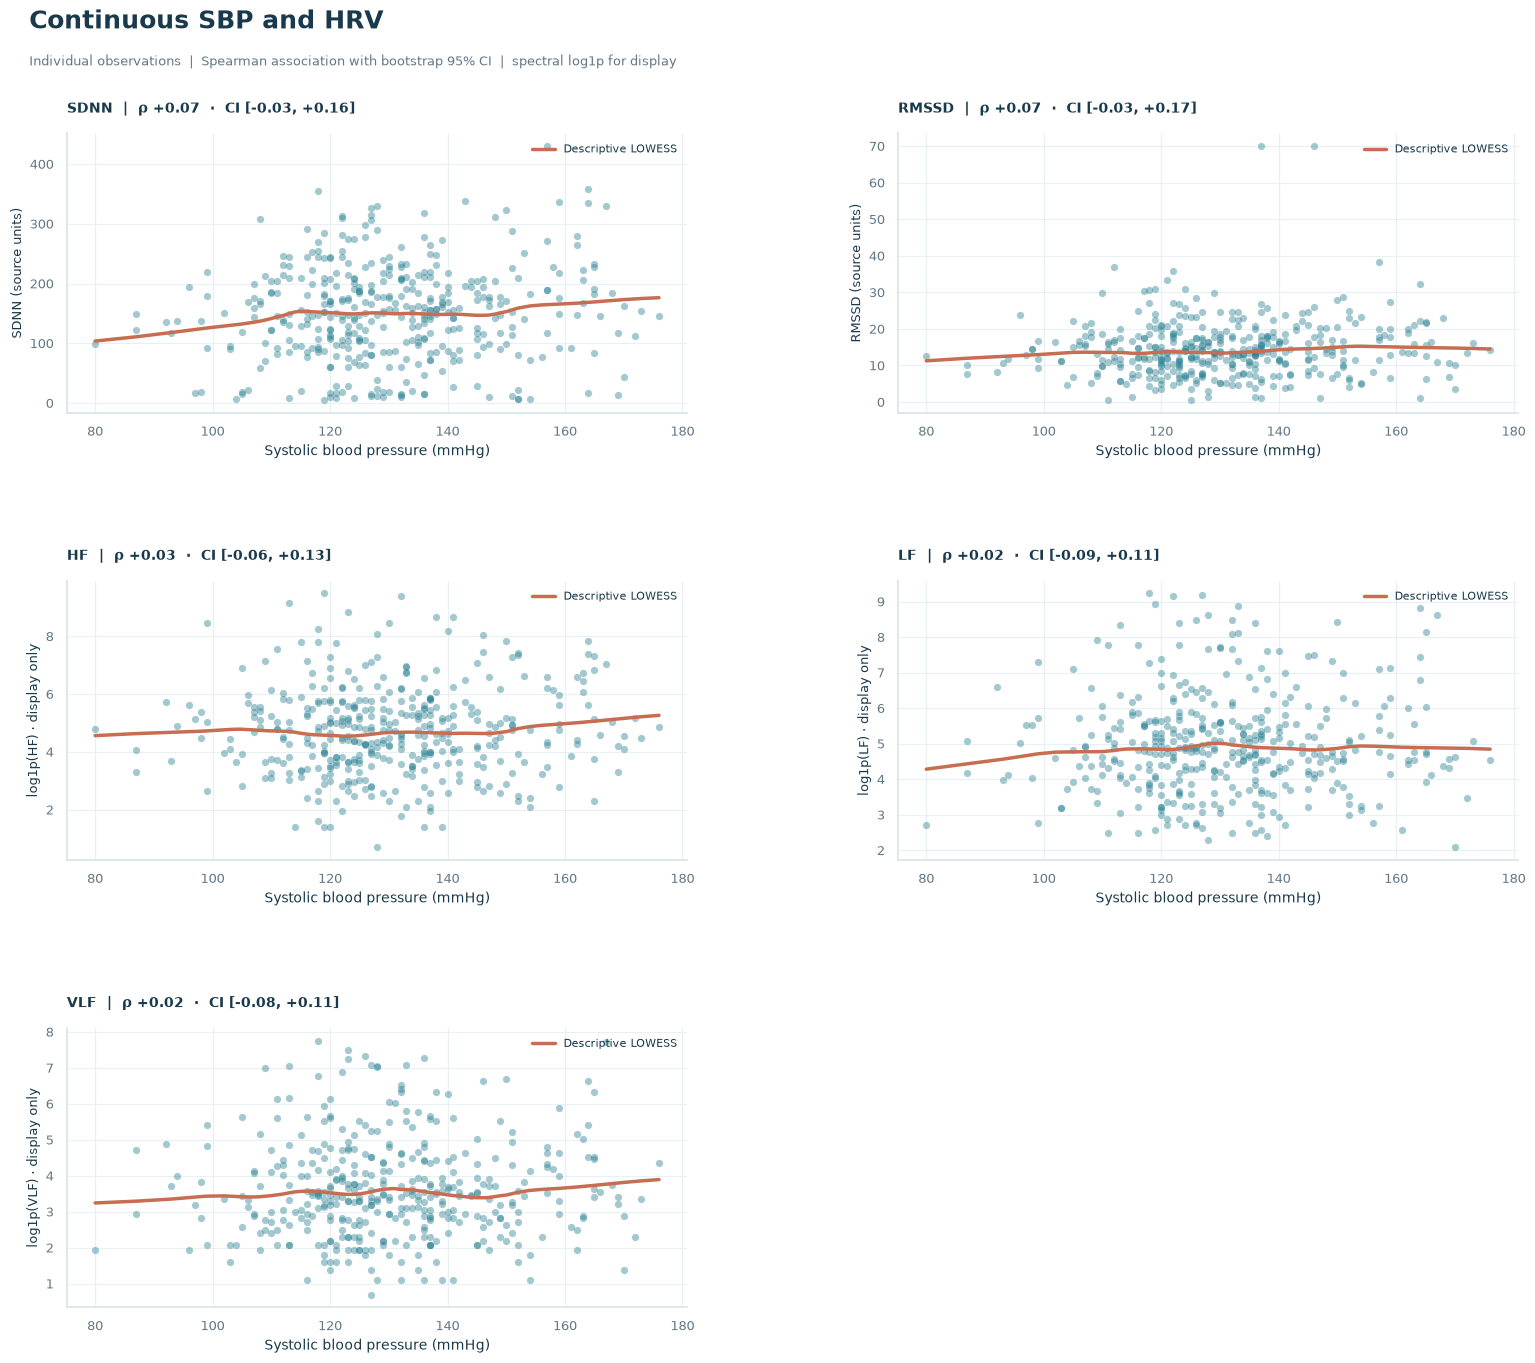

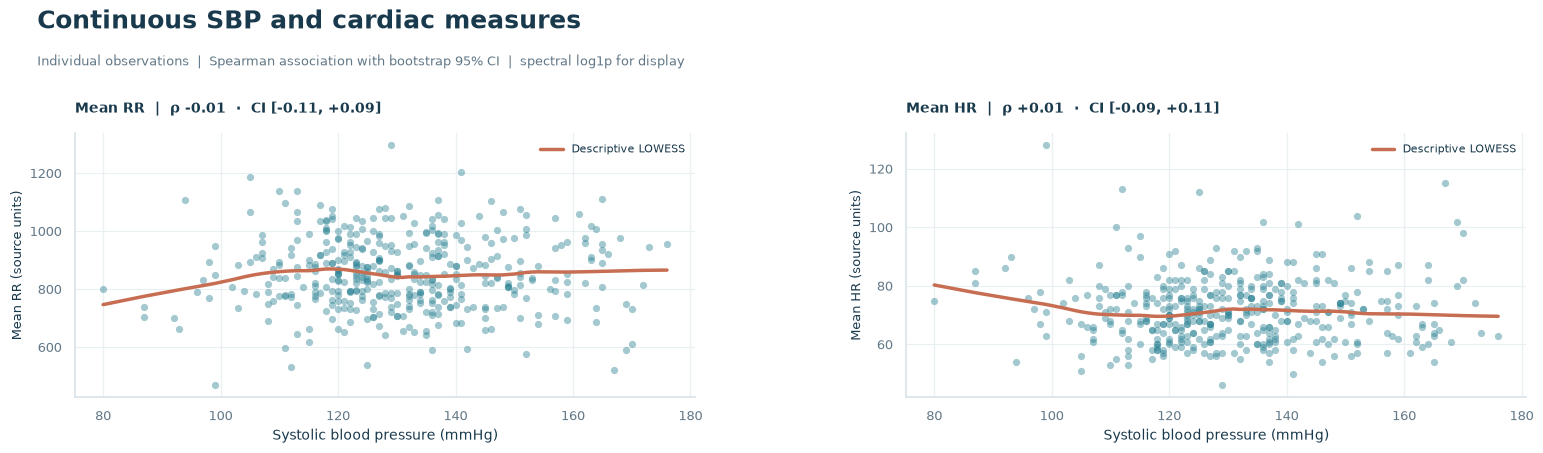

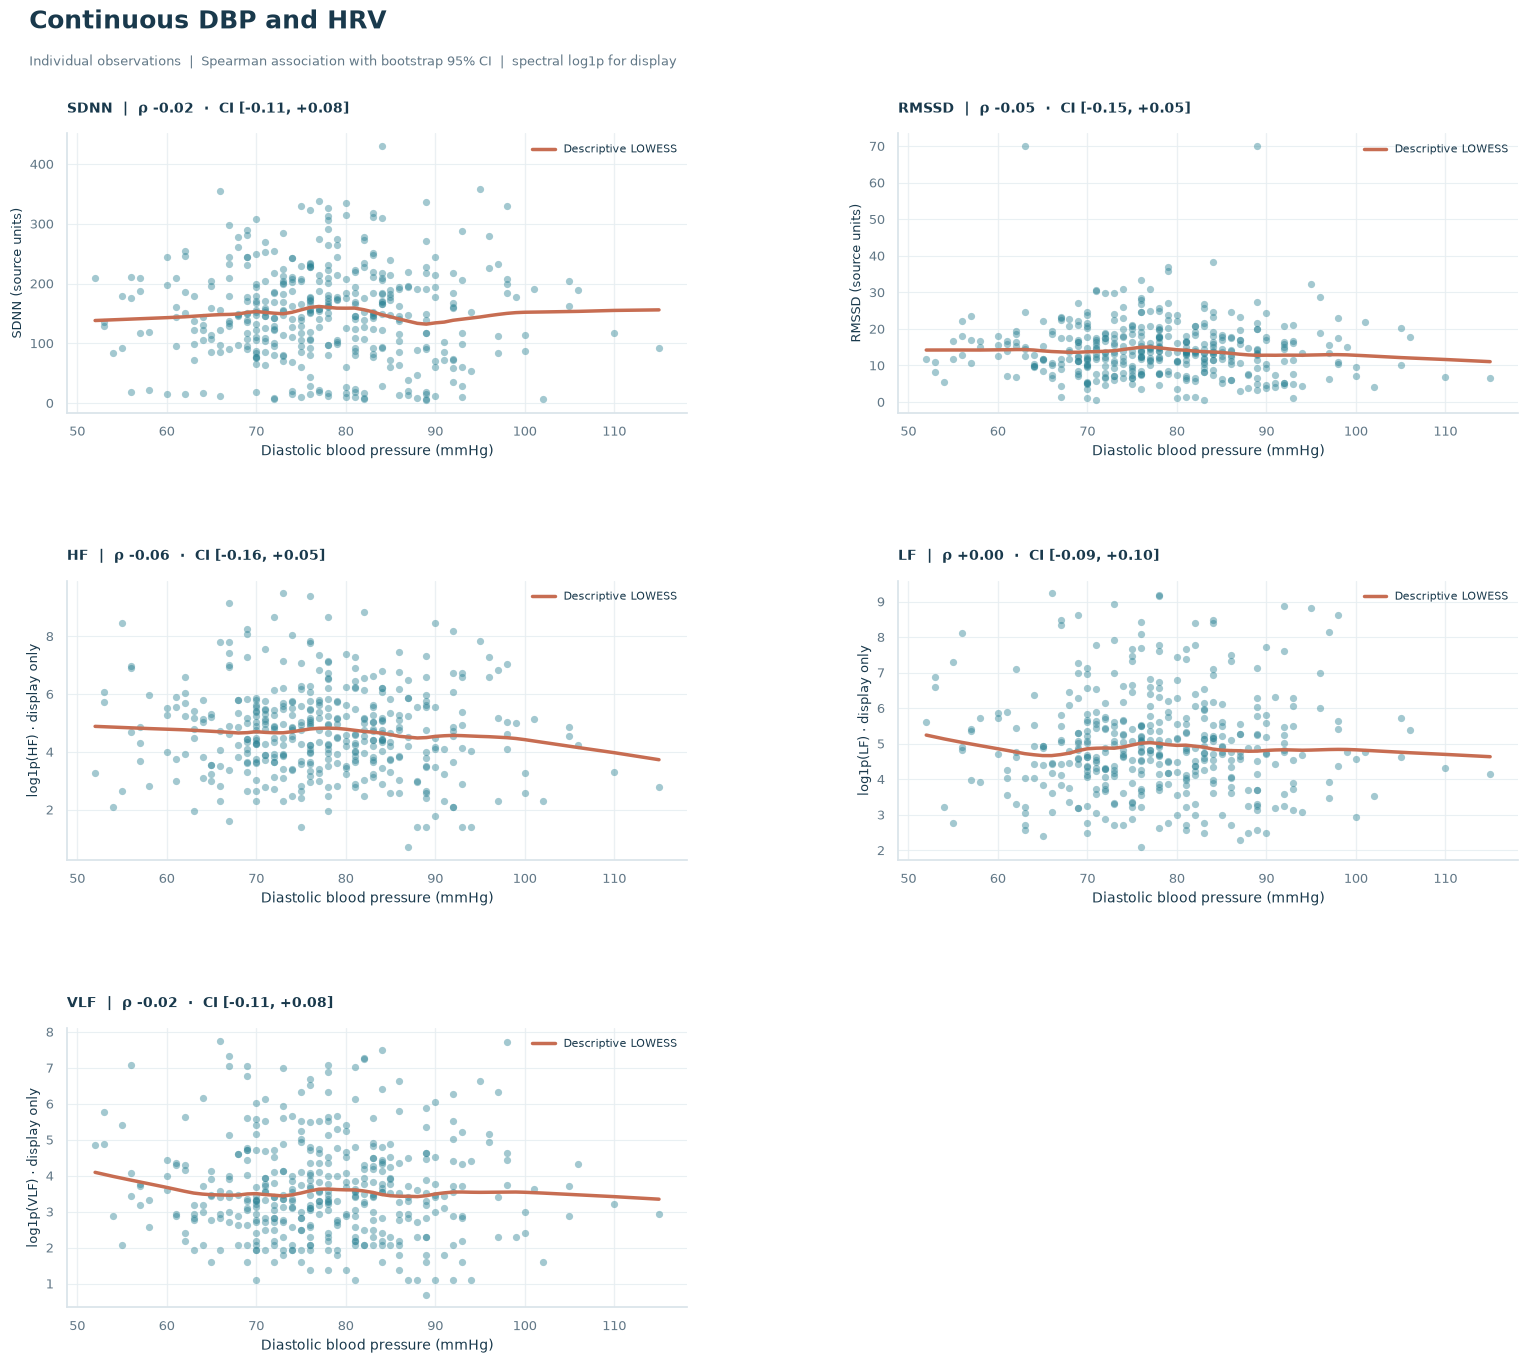

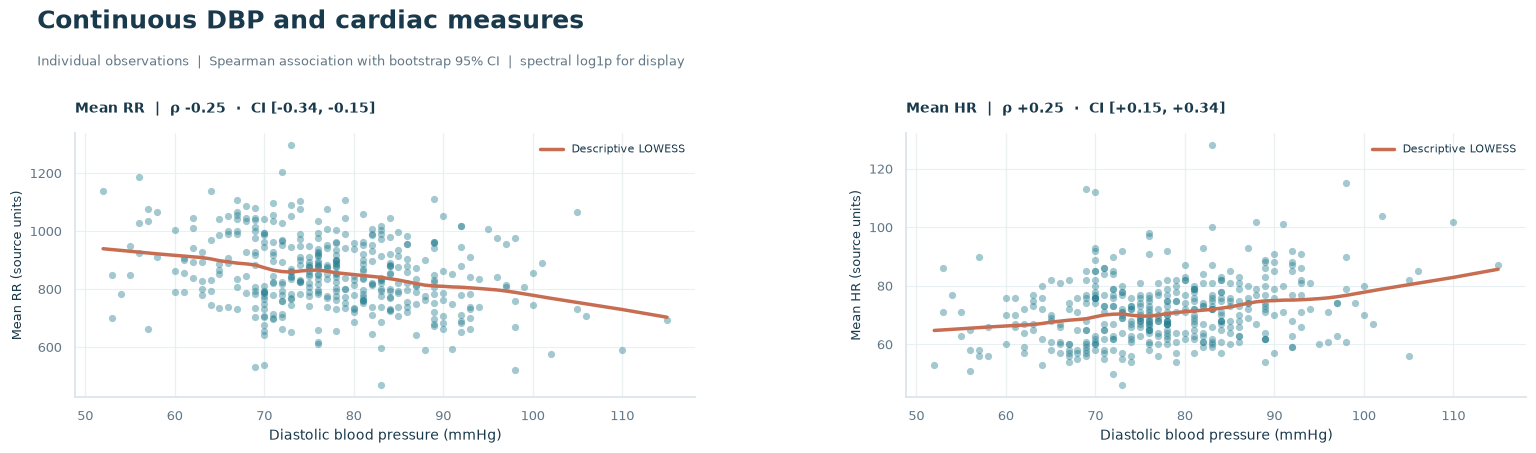

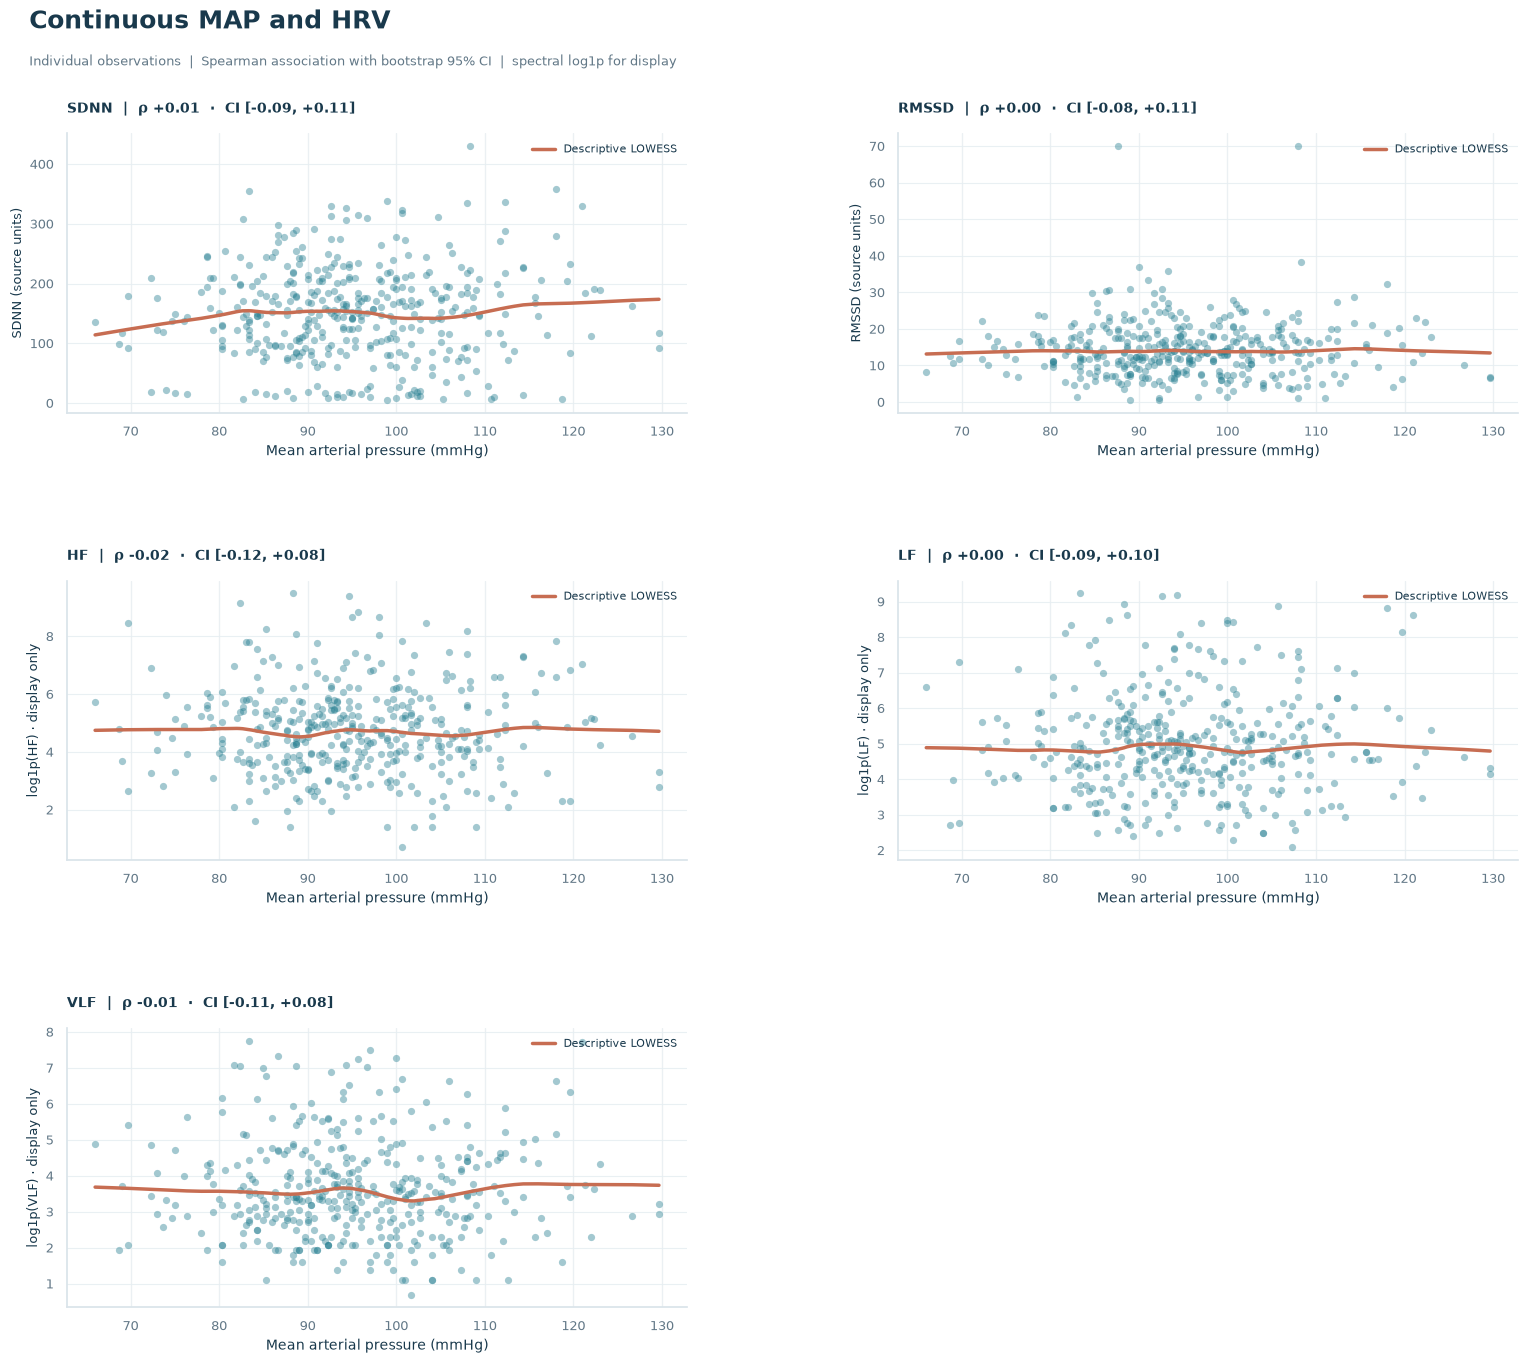

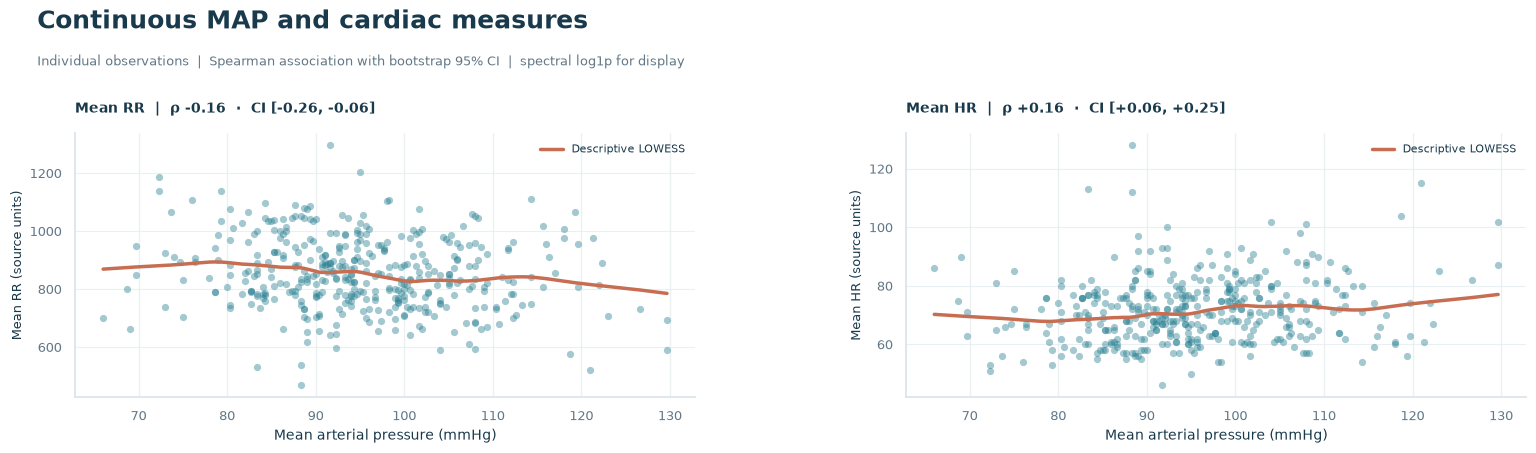

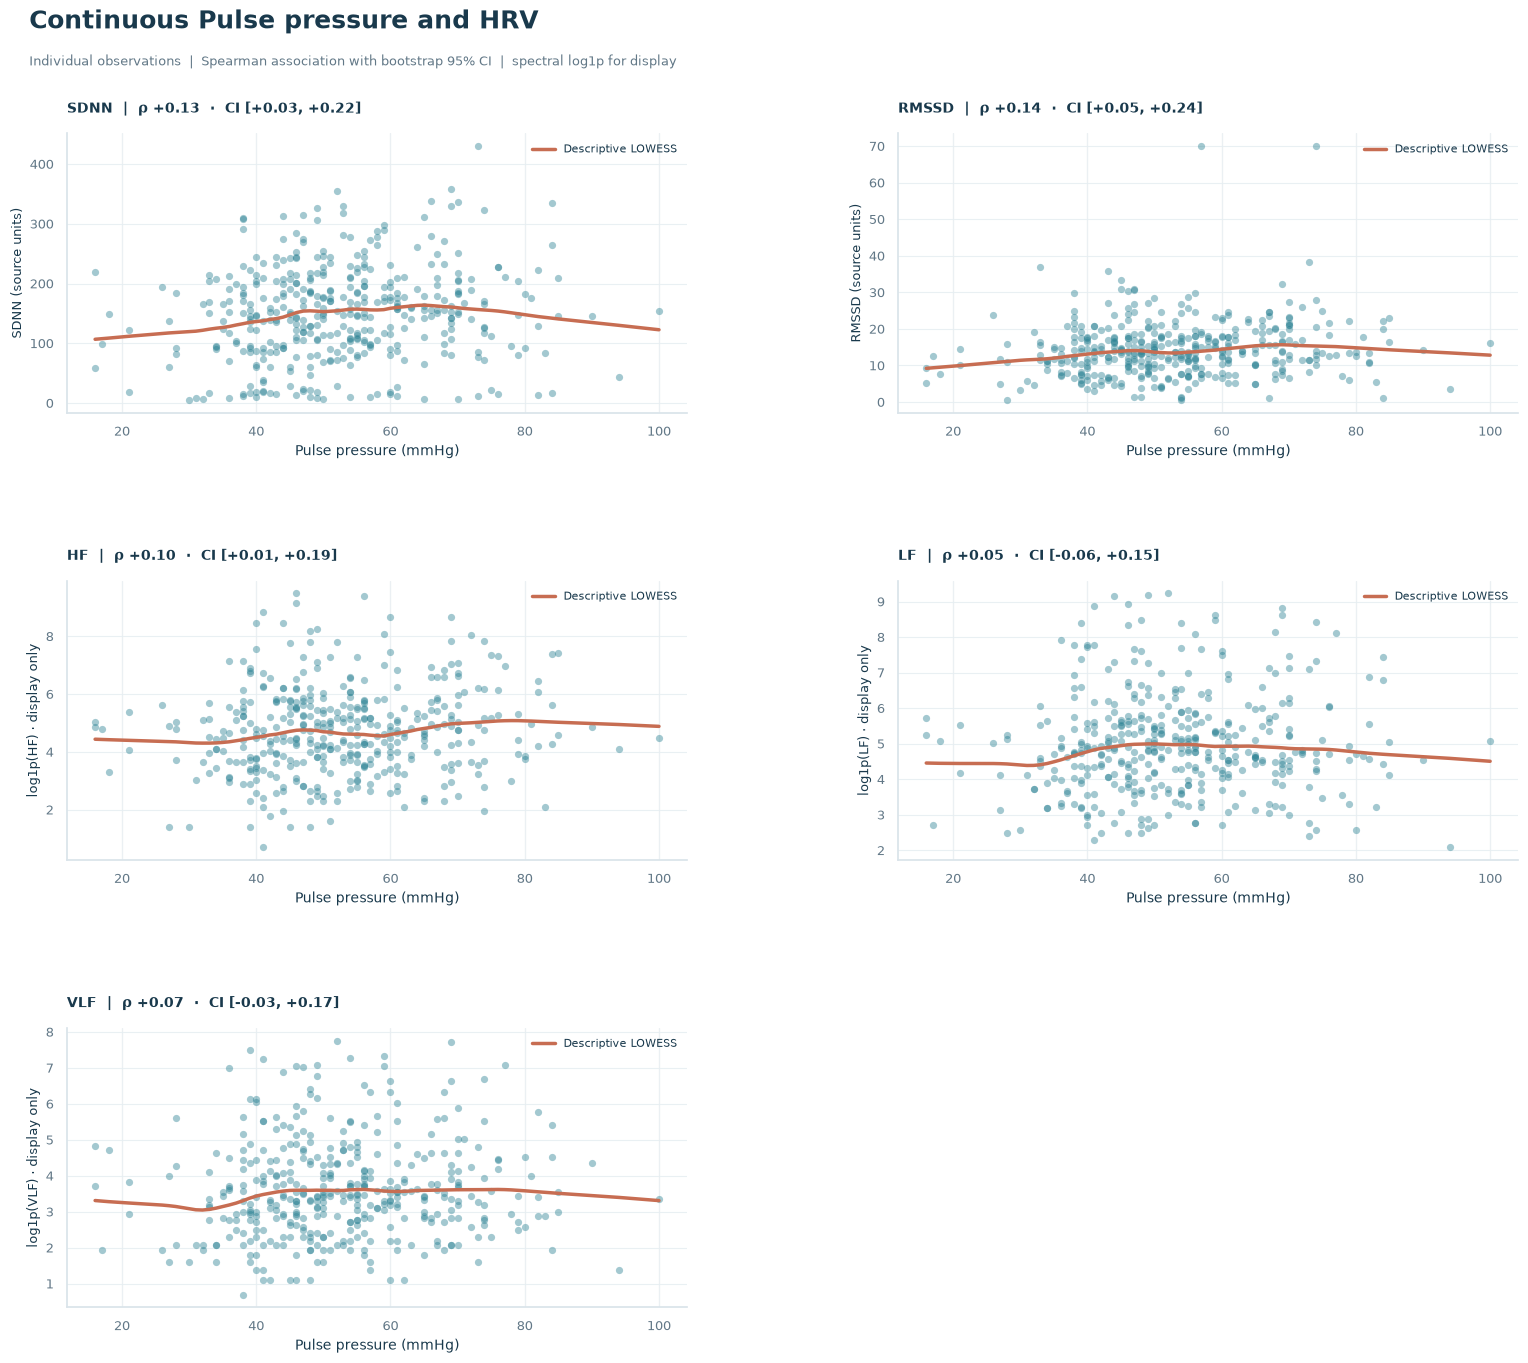

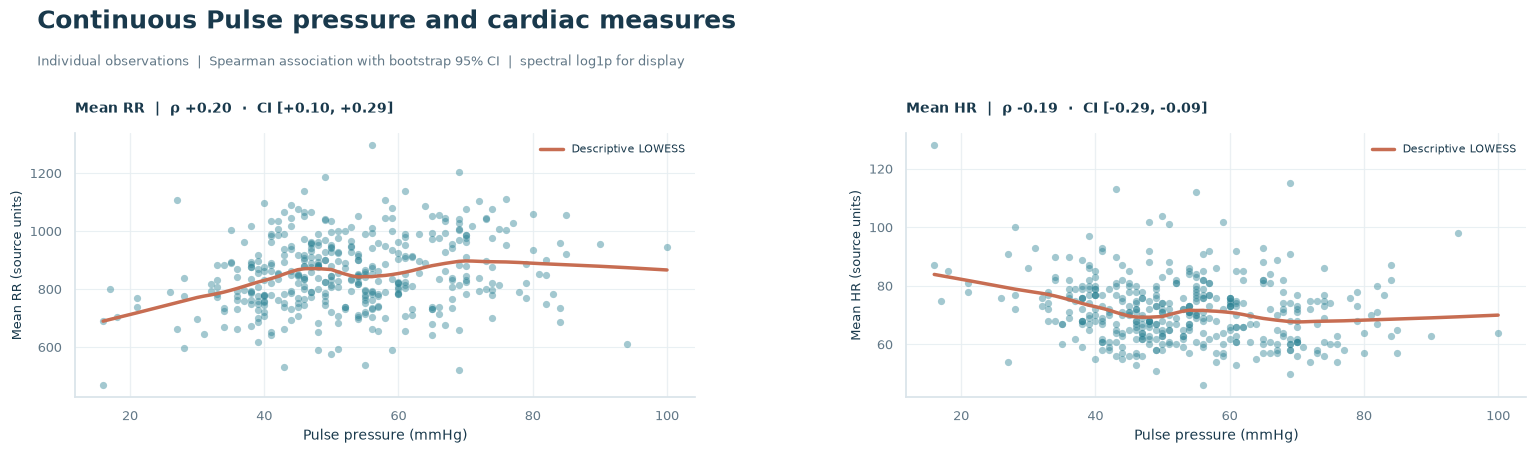

In [9]:
def scatter_sheet(factor, subset, filename):
    factor_label, factor_axis = CONTINUOUS[factor]
    selected = list(PRIMARY if subset == "primary" else COMPLEMENTARY)
    rows = int(np.ceil(len(selected) / 2))
    fig, axes = plt.subplots(rows, 2, figsize=(16.4, 4.55*rows + .25), squeeze=False)
    axes = axes.reshape(-1)
    x = data[factor].to_numpy(dtype=float)
    indexed = continuous.loc[continuous.factor == factor].set_index("outcome")
    for ax, outcome in zip(axes, selected):
        y, ylabel = values_for_plot(outcome)
        sns.scatterplot(x=x, y=y, color=TEAL, s=27, alpha=.42, linewidth=0, ax=ax)
        if LOWESS_AVAILABLE:
            trend = lowess(y, x, frac=.40, it=1, return_sorted=True)
            ax.plot(trend[:, 0], trend[:, 1], color=CORAL, lw=2.5, label="Descriptive LOWESS")
        result = indexed.loc[outcome]
        ax.set_title(f"{MEASURES[outcome]}  |  ρ {result.spearman_rho:+.2f}"
                     f"  ·  CI [{result.rho_ci_low:+.2f}, {result.rho_ci_high:+.2f}]",
                     fontsize=10.2, color=NAVY, loc="left", pad=15)
        ax.set_xlabel(factor_axis, fontsize=10)
        ax.set_ylabel(ylabel, fontsize=9.5)
        if LOWESS_AVAILABLE:
            ax.legend(frameon=False, loc="upper right", fontsize=8)
        style_axis(ax)
    for ax in axes[len(selected):]:
        ax.axis("off")
    figure_header(fig, f"Continuous {factor_label} and {'HRV' if subset == 'primary' else 'cardiac measures'}",
                  "Individual observations  |  Spearman association with bootstrap 95% CI  |  spectral log1p for display")
    plot_area(fig, left=.085, bottom_inches=.78, top_inches=1.38, hspace=.60)
    save_figure(fig, filename, f"Continuous {factor_label}: {subset} measures, scatterplots and optional LOWESS")


for i, (factor, (label, _)) in enumerate(CONTINUOUS.items(), start=1):
    tag = {"bp_systolic": "sbp", "bp_diastolic": "dbp", "bp_pam": "map", "bp_pp": "pulse_pressure"}[factor]
    scatter_sheet(factor, "primary", f"{2*i-1:02d}_{tag}_primary_hrv_scatter.png")
    scatter_sheet(factor, "complementary", f"{2*i:02d}_{tag}_complementary_scatter.png")

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


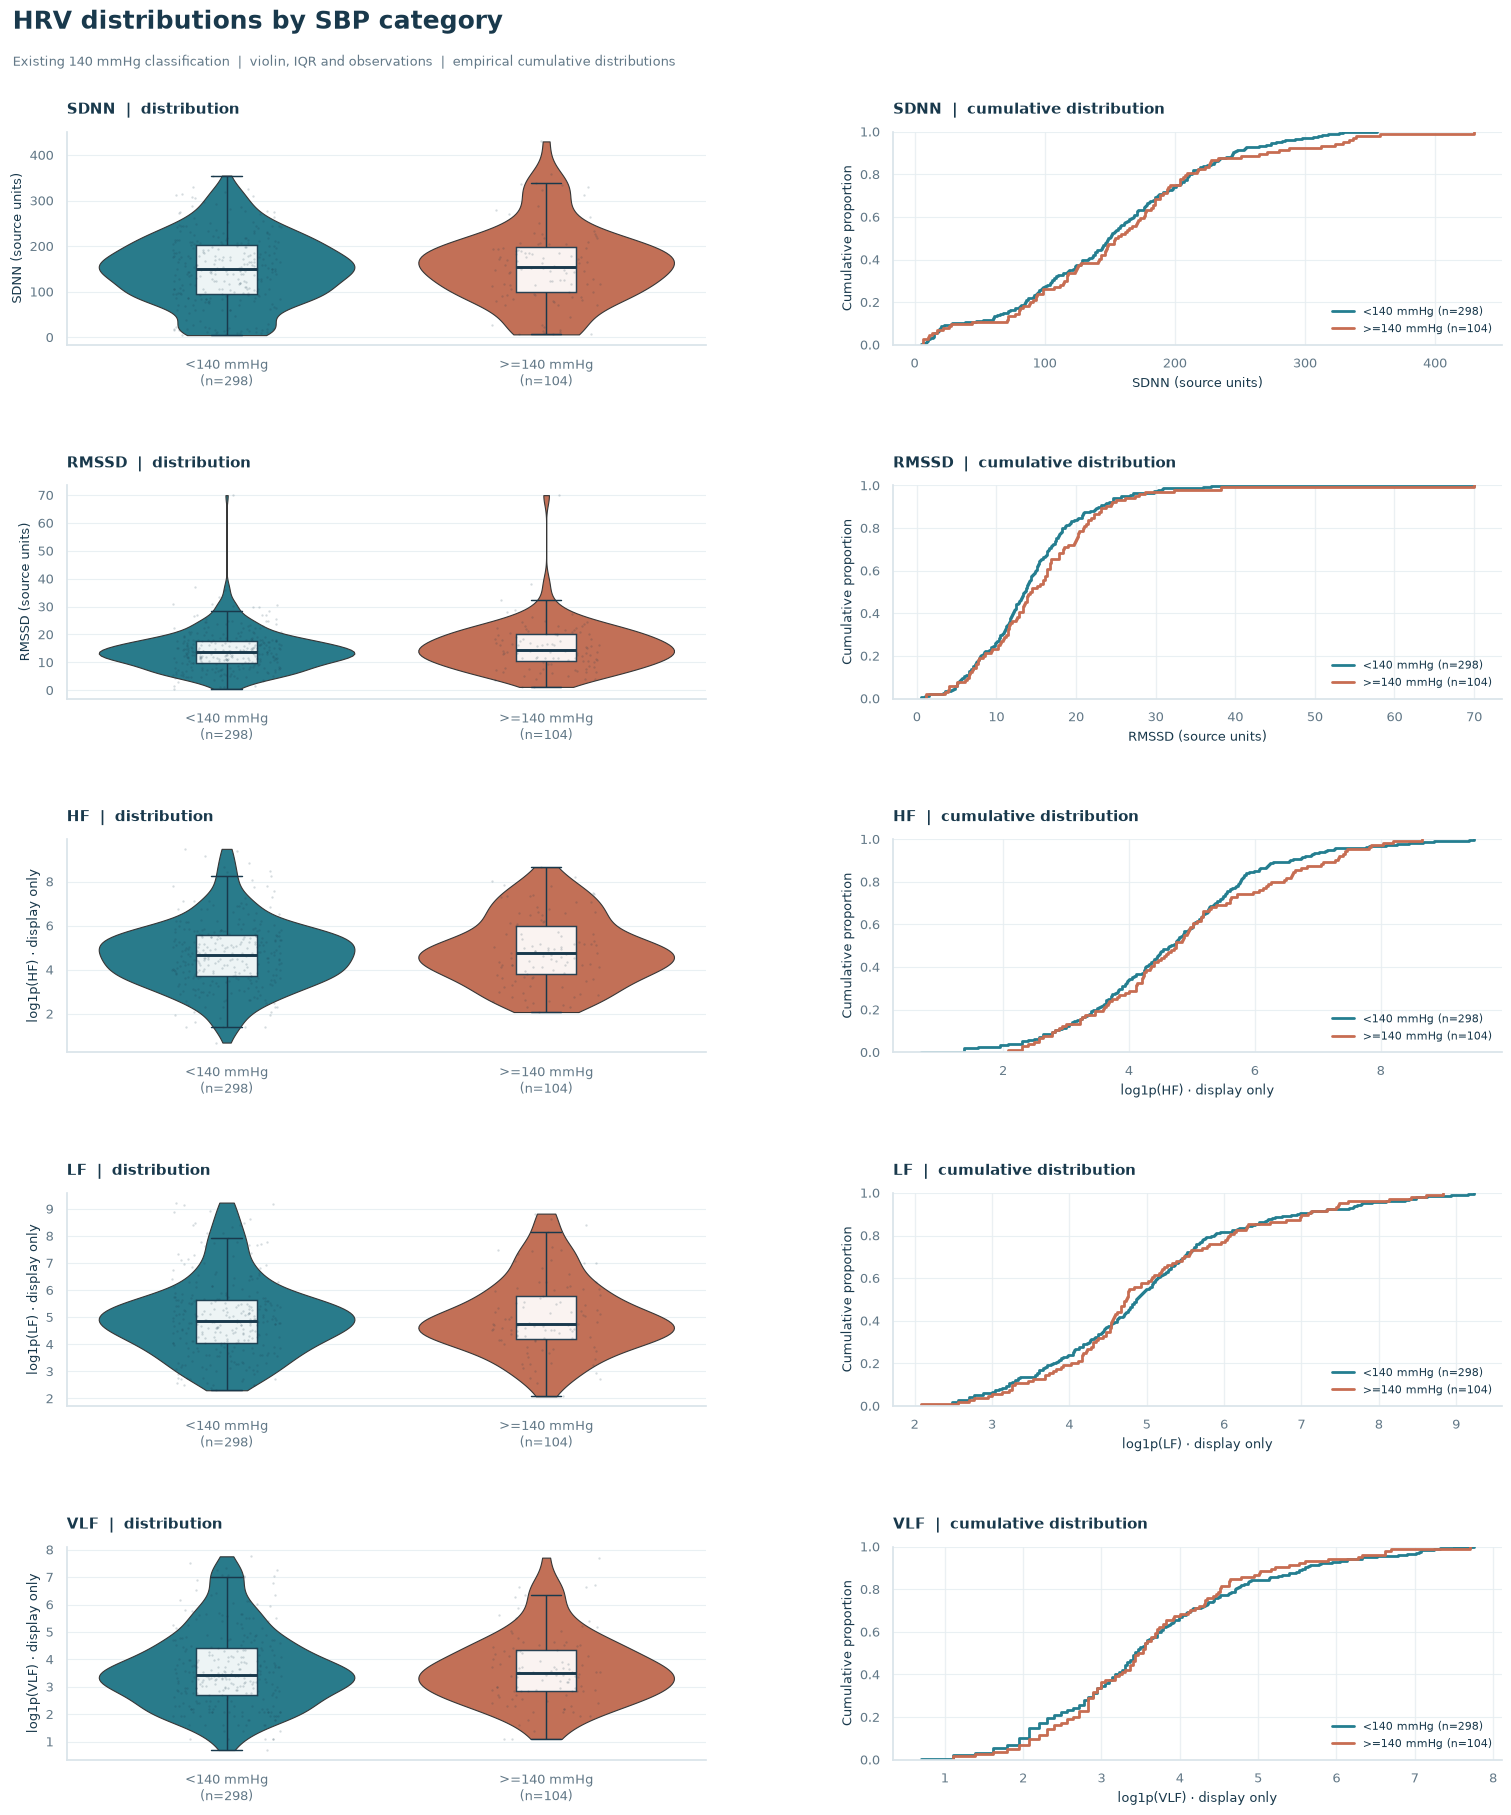

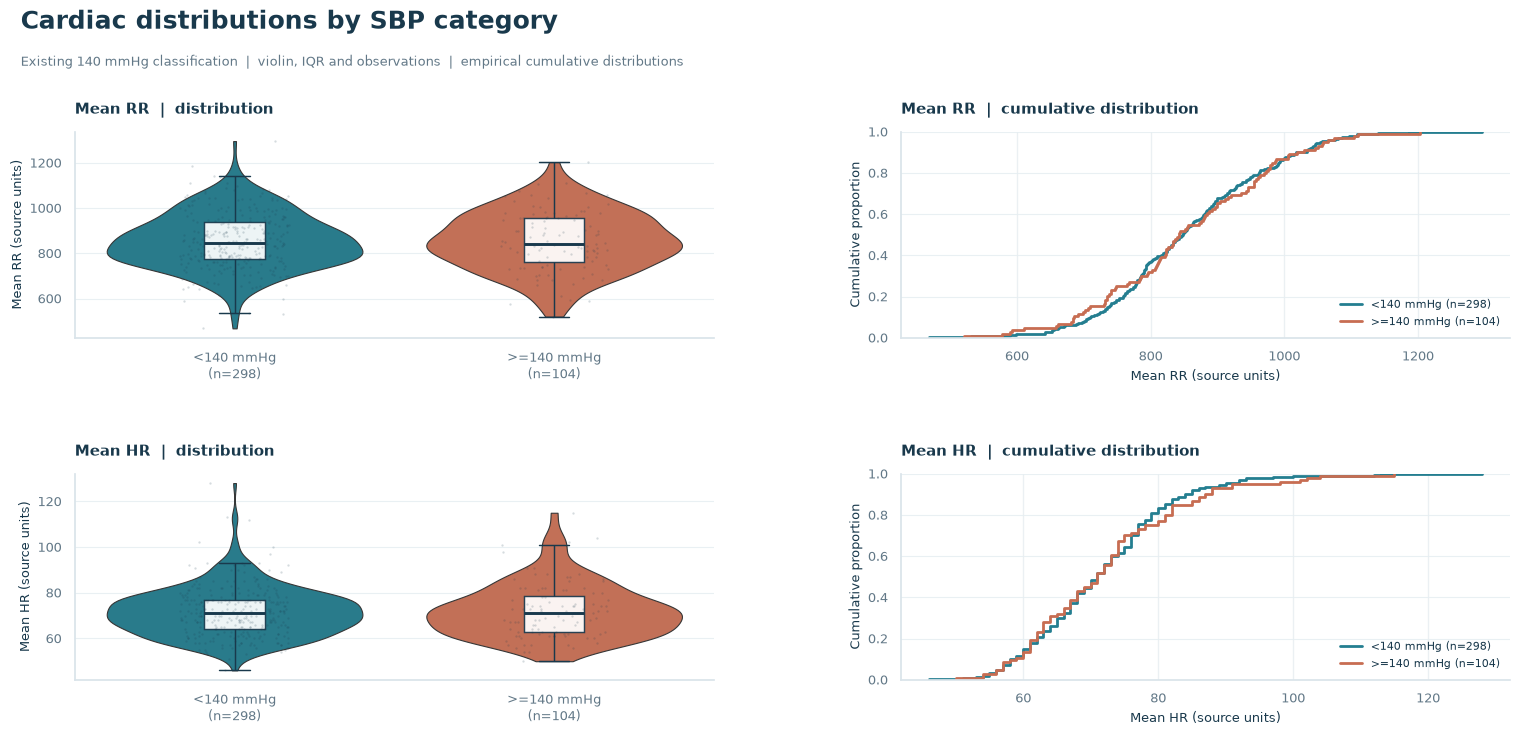

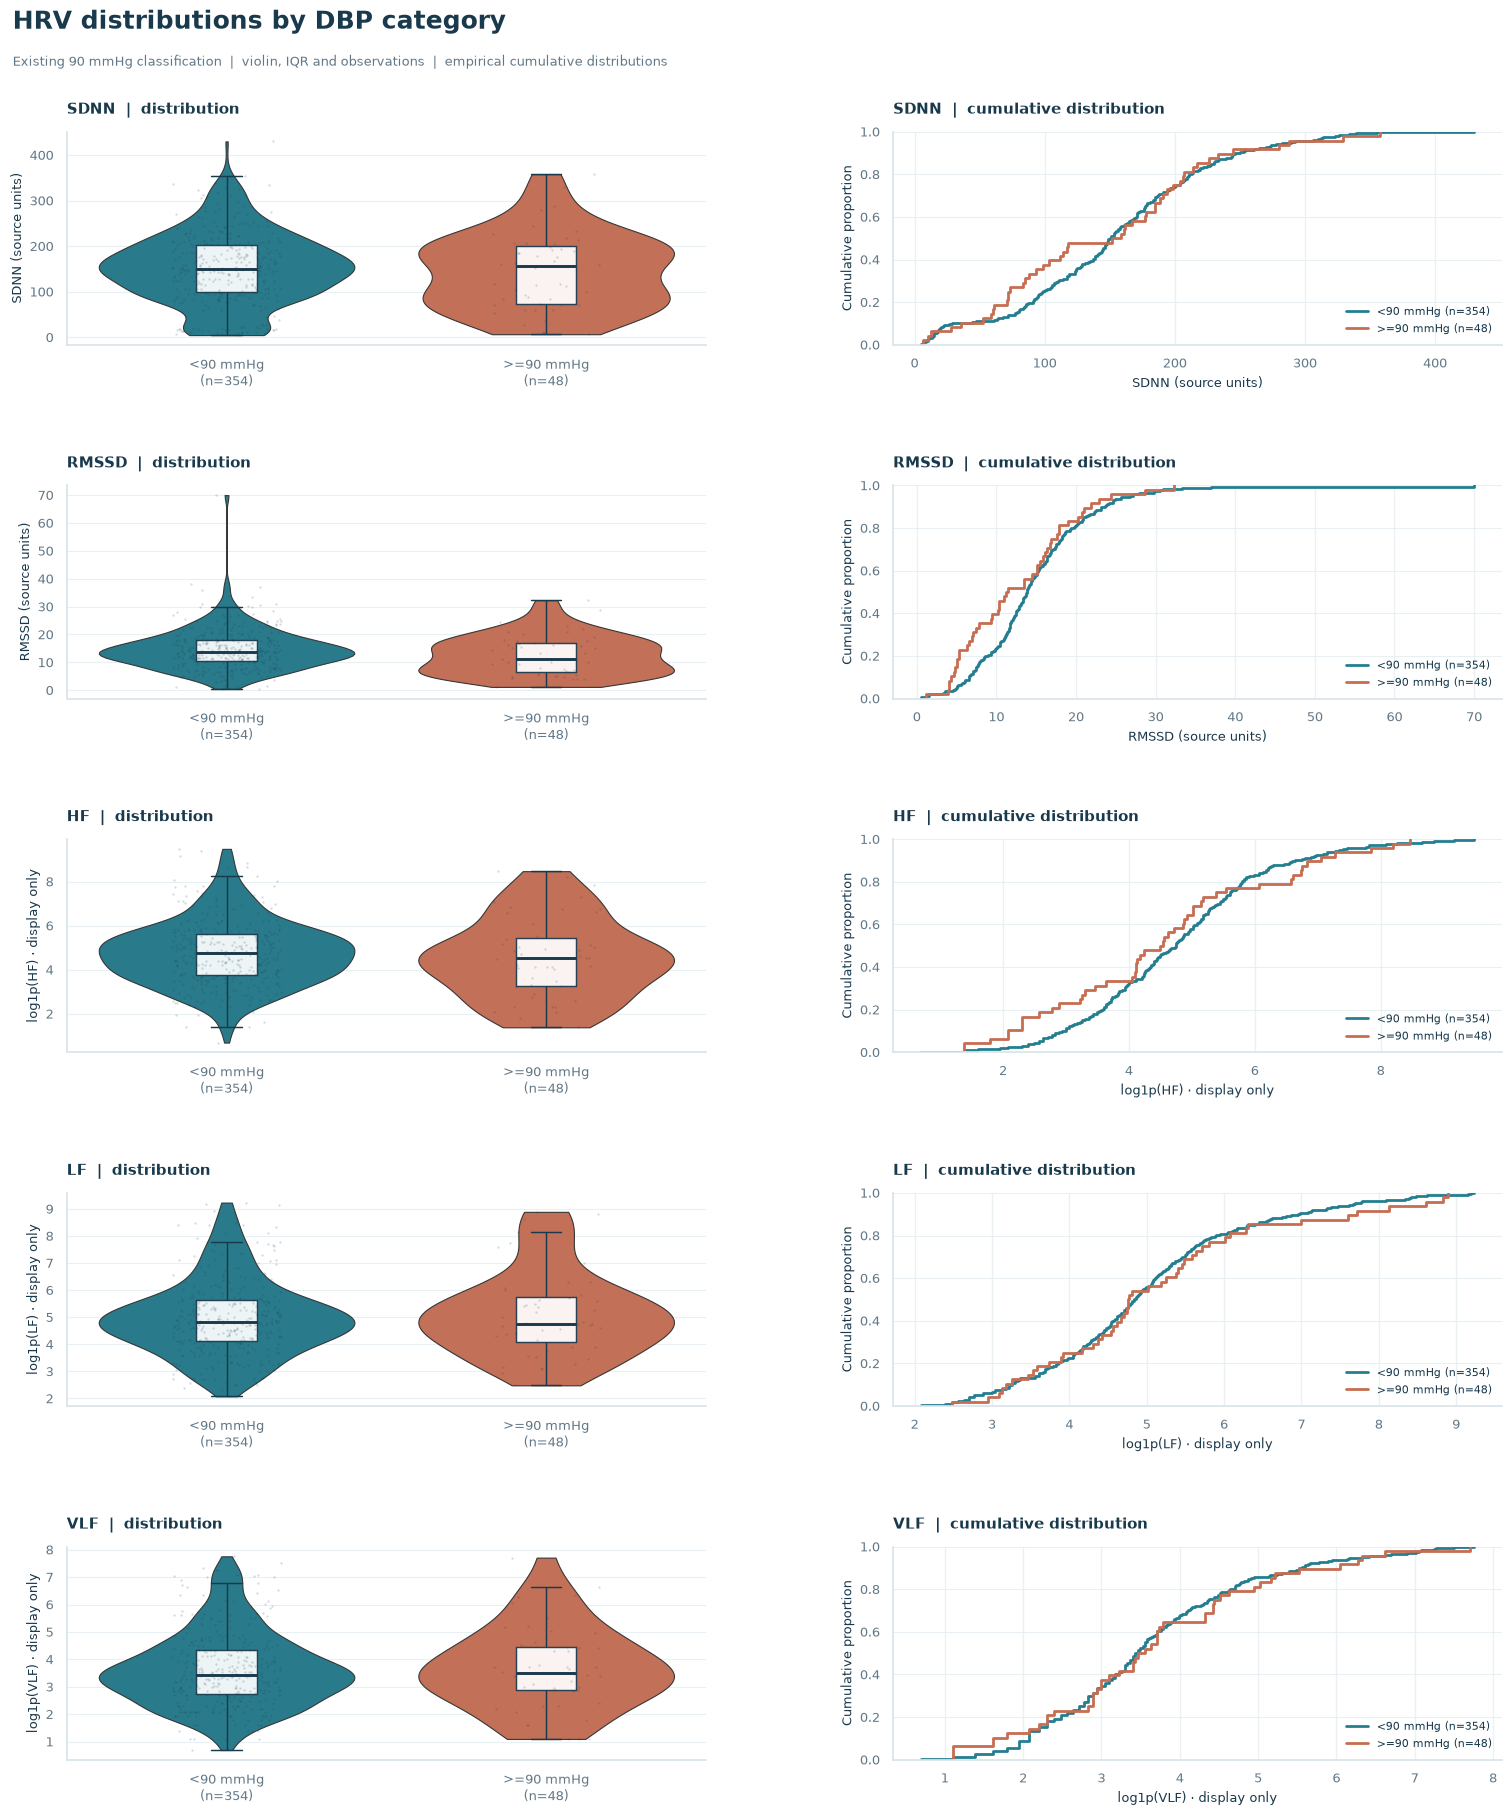

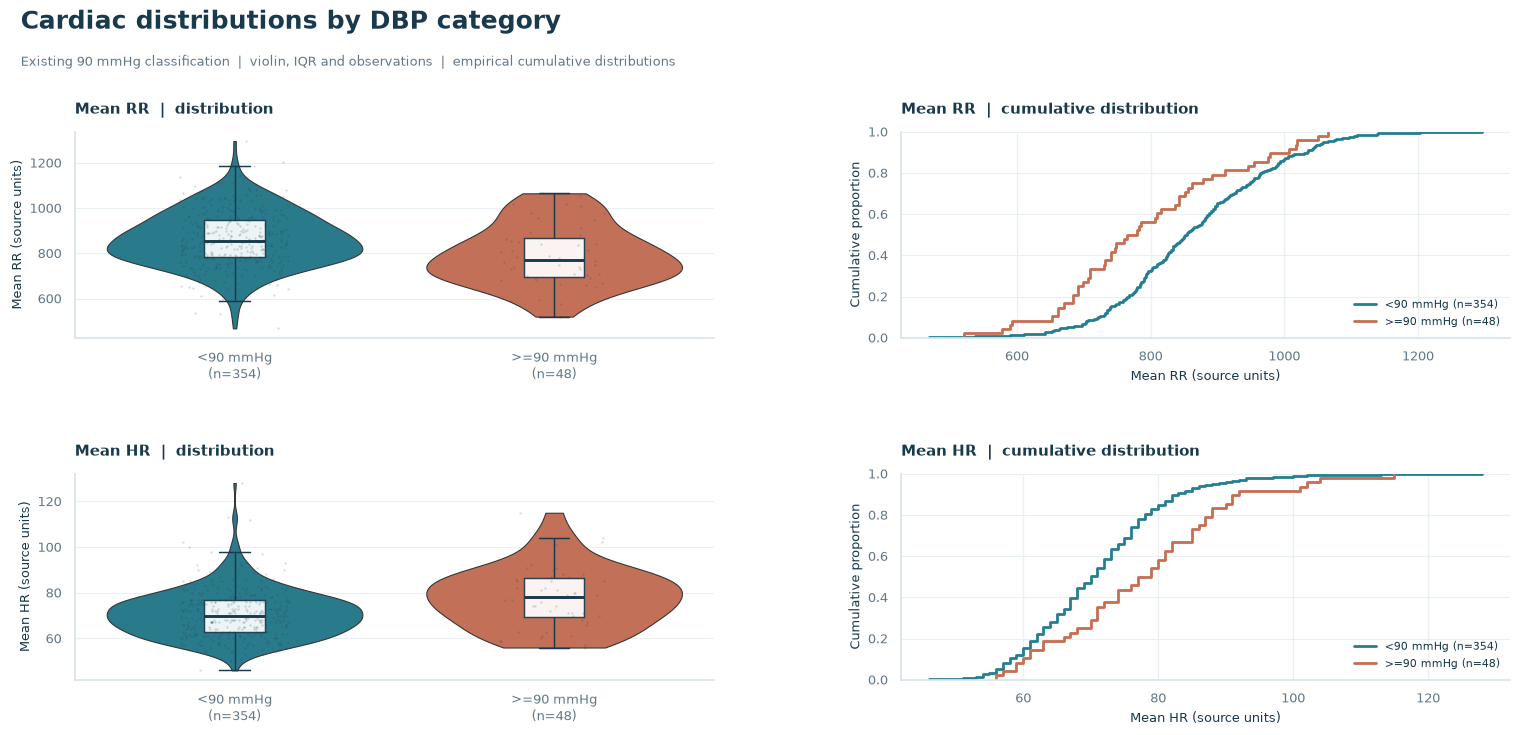

In [10]:
def categorical_distribution_sheet(factor, subset, filename):
    spec = CATEGORIES[factor]
    levels = spec["levels"]
    selected = list(PRIMARY if subset == "primary" else COMPLEMENTARY)
    rows = len(selected)
    fig, axes = plt.subplots(rows, 2, figsize=(16.4, 3.60*rows + .50), squeeze=False,
                             gridspec_kw={"width_ratios": [1.05, 1]})
    group_sizes = data[factor].value_counts().reindex(levels)
    palette = {level: CATEGORY_COLORS[level] for level in levels}
    for i, outcome in enumerate(selected):
        ax_dist, ax_ecdf = axes[i]
        vals, ylabel = values_for_plot(outcome)
        frame = pd.DataFrame({"category": data[factor].to_numpy(), "value": vals})
        sns.violinplot(data=frame, x="category", y="value", order=levels, hue="category",
                       palette=palette, legend=False, density_norm="width", cut=0,
                       inner=None, linewidth=.8, saturation=.91, ax=ax_dist)
        sns.boxplot(data=frame, x="category", y="value", order=levels, width=.19,
                    showfliers=False, color="white", linewidth=1.05,
                    boxprops={"edgecolor": NAVY, "facecolor": "white", "alpha": .92},
                    whiskerprops={"color": NAVY}, medianprops={"color": NAVY, "linewidth": 2.1},
                    capprops={"color": NAVY}, ax=ax_dist)
        sns.stripplot(data=frame, x="category", y="value", order=levels, color=NAVY,
                      size=1.65, alpha=.18, jitter=.17, ax=ax_dist)
        ax_dist.set_xticks(range(len(levels)), [f"{g}\n(n={group_sizes[g]})" for g in levels])
        ax_dist.set_xlabel("")
        ax_dist.set_ylabel(ylabel, fontsize=9.1)
        ax_dist.set_title(f"{MEASURES[outcome]}  |  distribution", loc="left", fontsize=10.8, pad=13)

        for category in levels:
            v = frame.loc[frame.category == category, "value"]
            sns.ecdfplot(x=v, ax=ax_ecdf, linewidth=2.0, color=palette[category],
                         label=f"{category} (n={group_sizes[category]})")
        ax_ecdf.set_title(f"{MEASURES[outcome]}  |  cumulative distribution", loc="left", fontsize=10.8, pad=13)
        ax_ecdf.set_xlabel(ylabel, fontsize=9.1)
        ax_ecdf.set_ylabel("Cumulative proportion", fontsize=9.1)
        ax_ecdf.legend(frameon=False, fontsize=8, loc="lower right")
        for ax in [ax_dist, ax_ecdf]:
            style_axis(ax)

    figure_header(fig, f"{'HRV' if subset == 'primary' else 'Cardiac'} distributions by {spec['name']}",
                  f"Existing {spec['threshold']} classification  |  violin, IQR and observations  |  empirical cumulative distributions")
    plot_area(fig, left=.095, bottom_inches=.86, top_inches=1.36, wspace=.30, hspace=.66)
    save_figure(fig, filename, f"{spec['name']} profiles for {subset} outcomes, with ECDF")


for factor, tag, numbers in [("sbp_category", "sbp", (9,10)), ("dbp_category", "dbp", (11,12))]:
    categorical_distribution_sheet(factor, "primary", f"{numbers[0]:02d}_{tag}_category_primary_hrv_profiles.png")
    categorical_distribution_sheet(factor, "complementary", f"{numbers[1]:02d}_{tag}_category_complementary_profiles.png")

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


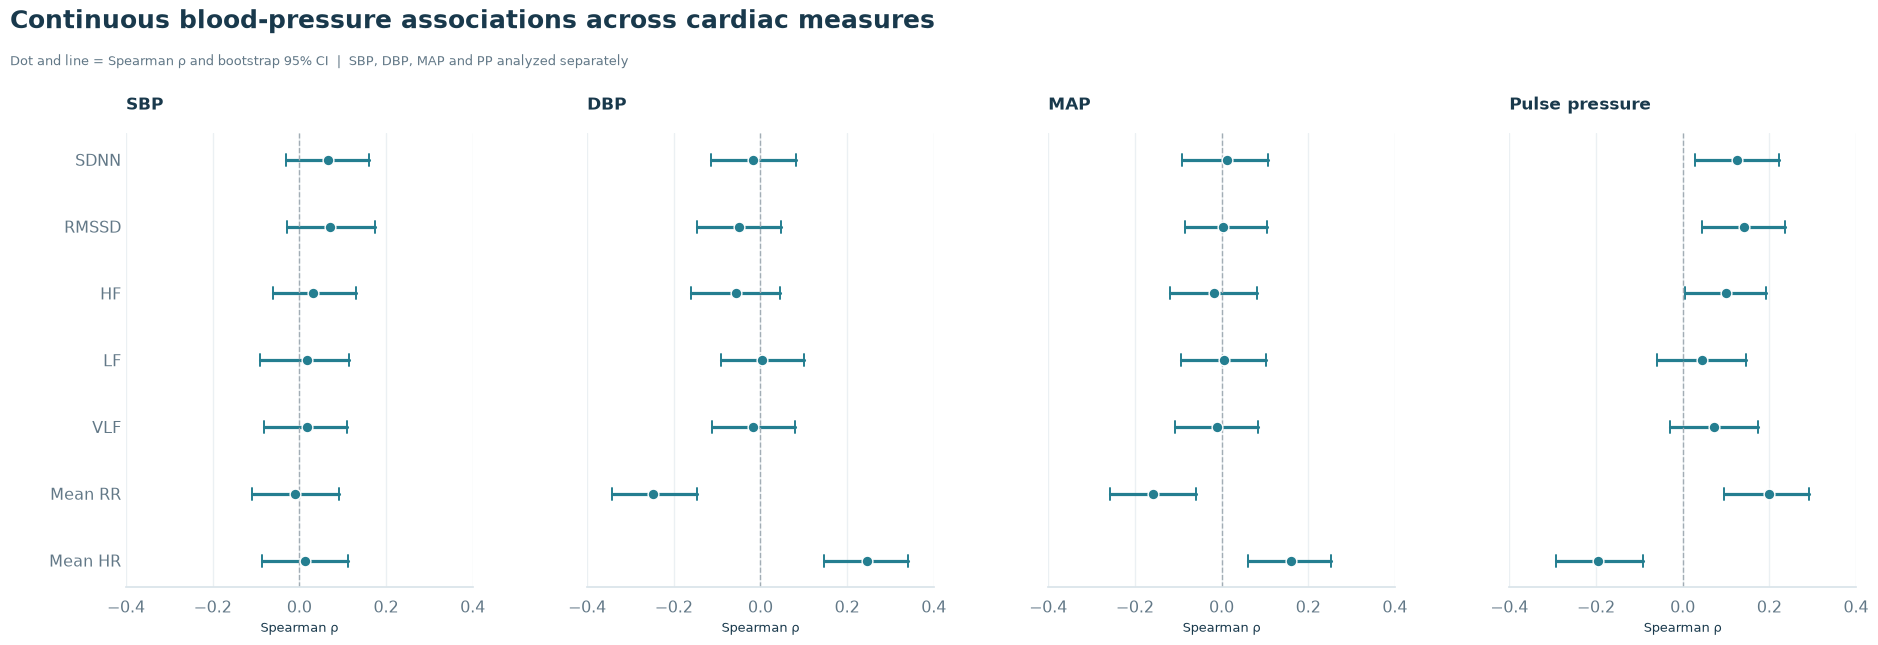

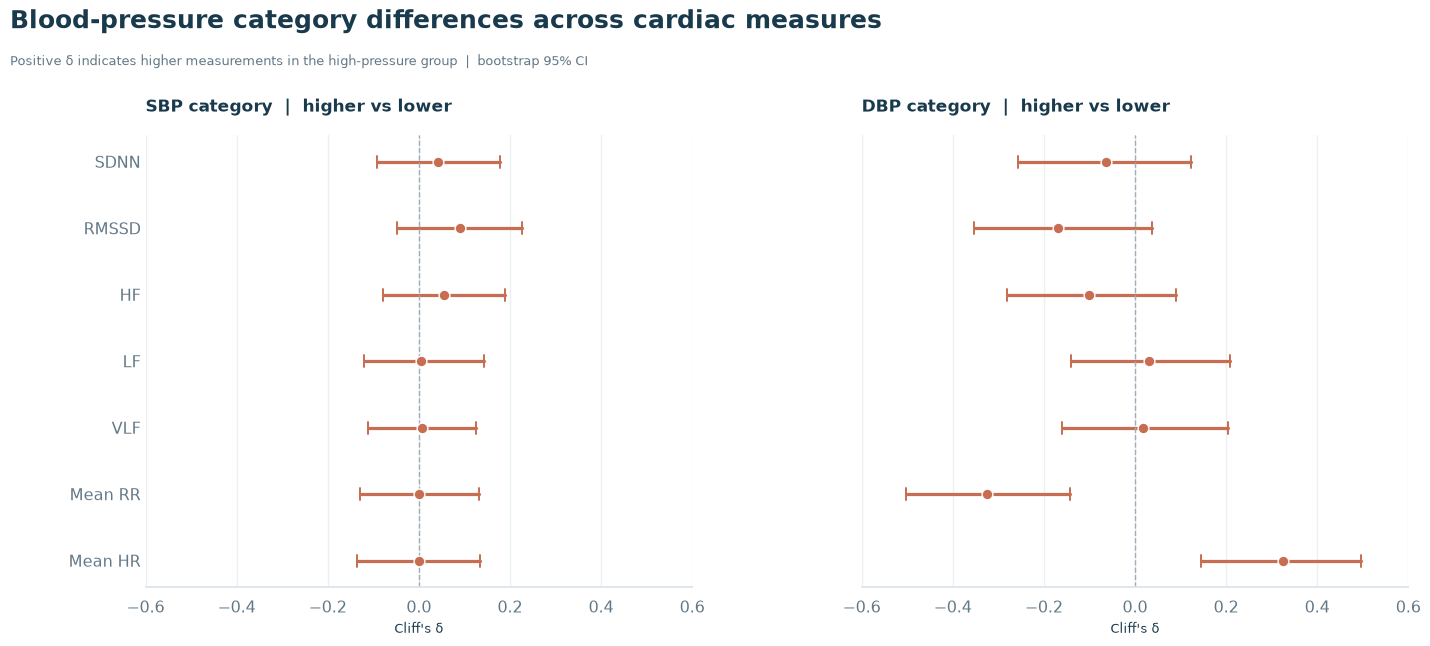

In [11]:
def forest_panel(ax, estimates, low_col, high_col, effect_col, labels, color, xlim, xlabel):
    positions = np.arange(len(estimates))[::-1]
    center = estimates[effect_col].to_numpy(dtype=float)
    low = estimates[low_col].to_numpy(dtype=float)
    high = estimates[high_col].to_numpy(dtype=float)
    for ypos, value, lo, hi in zip(positions, center, low, high):
        ax.plot([lo, hi], [ypos, ypos], lw=2.3, color=color, solid_capstyle="round")
        ax.plot([lo, lo], [ypos-.09, ypos+.09], lw=1.4, color=color)
        ax.plot([hi, hi], [ypos-.09, ypos+.09], lw=1.4, color=color)
        ax.scatter(value, ypos, s=60, color=color, edgecolors="white", zorder=3)
    ax.axvline(0, color="#A2ADB5", lw=1, ls="--")
    ax.set_yticks(positions, labels)
    ax.set_xlim(*xlim)
    ax.set_xlabel(xlabel, fontsize=9.5)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#E6EDF1")
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)


def blood_pressure_forest():
    fig, axes = plt.subplots(1, 4, figsize=(20.0, 6.8), sharey=True)
    names = list(MEASURES.values())
    observed_limit = np.nanmax(np.abs(continuous[["rho_ci_low", "rho_ci_high"]].to_numpy(dtype=float)))
    rho_extent = float(min(1, max(.3, np.ceil((observed_limit + .04) * 10) / 10)))
    for ax, (factor, (label, _)) in zip(axes, CONTINUOUS.items()):
        chosen = continuous.loc[continuous.factor == factor].set_index("outcome").loc[list(MEASURES)].reset_index()
        forest_panel(ax, chosen, "rho_ci_low", "rho_ci_high", "spearman_rho",
                     names, TEAL, (-rho_extent, rho_extent), "Spearman ρ")
        ax.set_title(label, fontsize=12, color=NAVY, loc="left", pad=17)
    figure_header(fig, "Continuous blood-pressure associations across cardiac measures",
                  "Dot and line = Spearman ρ and bootstrap 95% CI  |  SBP, DBP, MAP and PP analyzed separately")
    plot_area(fig, left=.12, right=.985, bottom_inches=.88, top_inches=1.38, wspace=.33)
    save_figure(fig, "13_blood_pressure_spearman_forest.png",
                "Forest comparisons of four continuous blood-pressure factor associations")


def categorical_effect_forest():
    fig, axes = plt.subplots(1, 2, figsize=(15.4, 6.8), sharey=True)
    names = list(MEASURES.values())
    observed_limit = np.nanmax(np.abs(binary[["cliffs_ci_low", "cliffs_ci_high"]].to_numpy(dtype=float)))
    delta_extent = float(min(1, max(.3, np.ceil((observed_limit + .04) * 10) / 10)))
    for ax, (factor, spec) in zip(axes, CATEGORIES.items()):
        chosen = binary.loc[binary.factor == factor].set_index("outcome").loc[list(MEASURES)].reset_index()
        forest_panel(ax, chosen, "cliffs_ci_low", "cliffs_ci_high", "cliffs_delta_high_vs_low",
                     names, CORAL, (-delta_extent, delta_extent), "Cliff's δ")
        ax.set_title(f"{spec['name']}  |  higher vs lower", fontsize=12, color=NAVY, loc="left", pad=17)
    figure_header(fig, "Blood-pressure category differences across cardiac measures",
                  "Positive δ indicates higher measurements in the high-pressure group  |  bootstrap 95% CI")
    plot_area(fig, left=.15, right=.97, bottom_inches=.88, top_inches=1.40, wspace=.31)
    save_figure(fig, "14_blood_pressure_category_cliffs_forest.png",
                "Cliff's delta estimates for high- versus low-pressure SBP and DBP categories")


blood_pressure_forest()
categorical_effect_forest()

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


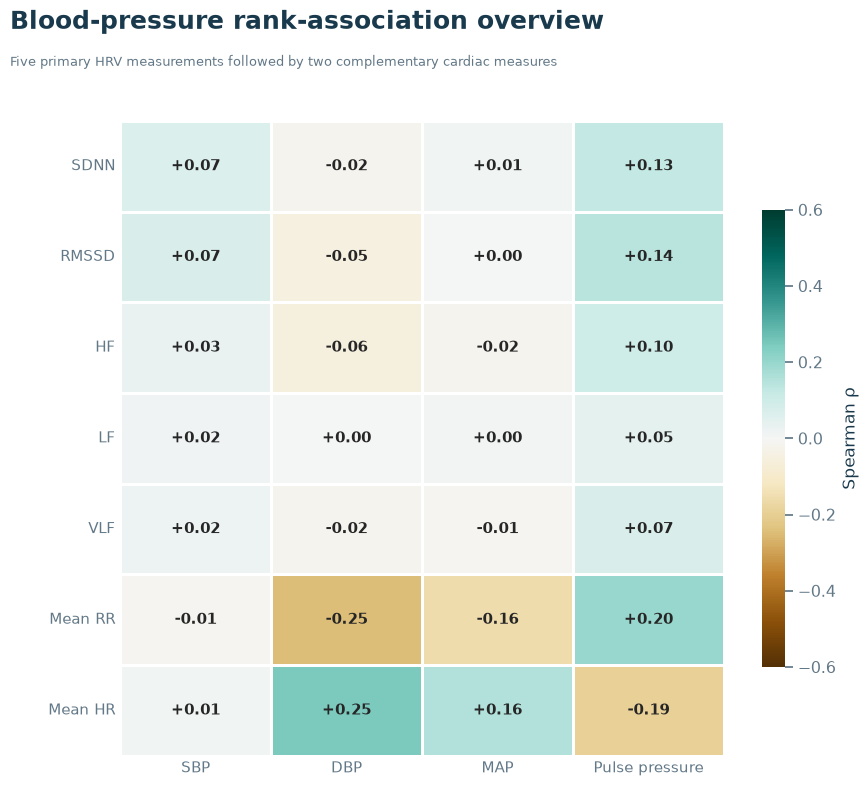

In [12]:
def association_heatmap():
    matrix = continuous.pivot(index="outcome_label", columns="factor_label", values="spearman_rho")
    matrix = matrix.reindex(index=list(MEASURES.values()), columns=[value[0] for value in CONTINUOUS.values()])
    fig, ax = plt.subplots(figsize=(10.2, 8.3))
    sns.heatmap(matrix, annot=True, fmt="+.2f", cmap="BrBG", center=0, vmin=-.6, vmax=.6,
                linewidths=1.8, linecolor="white", square=False,
                cbar_kws={"label": "Spearman ρ", "shrink": .72},
                annot_kws={"size": 11, "weight": "semibold"}, ax=ax)
    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.set_yticklabels(matrix.index, rotation=0, fontsize=11)
    ax.set_xticklabels(matrix.columns, rotation=0, fontsize=11)
    ax.tick_params(axis="both", length=0)
    figure_header(fig, "Blood-pressure rank-association overview",
                  "Five primary HRV measurements followed by two complementary cardiac measures")
    plot_area(fig, left=.17, right=.91, bottom_inches=.70, top_inches=1.25)
    save_figure(fig, "15_blood_pressure_spearman_heatmap.png",
                "Spearman estimates across four continuous blood-pressure factors and seven outcomes")


association_heatmap()

## 8. Manifest, methodological README and complete results report

The report includes **all** effect estimates and p-values, not only statistically significant associations. The methods README records the original category definitions, estimates, uncertainty methods, visualization conventions and interpretation boundaries.

In [13]:
save_table(pd.DataFrame(figure_manifest), "figure_manifest.csv")
run_info = pd.DataFrame([{
    "input_file": str(input_file), "n_records": len(data),
    "outcomes": " | ".join(MEASURES), "continuous_factors": " | ".join(CONTINUOUS),
    "category_factors": " | ".join(CATEGORIES),
    "bootstrap_replicates": N_BOOT, "seed": SEED, "confidence_level": CONFIDENCE_LEVEL,
    "python": platform.python_version(), "pandas": pd.__version__,
    "numpy": np.__version__, "scipy": __import__("scipy").__version__,
    "seaborn": sns.__version__, "matplotlib": matplotlib.__version__,
    "lowess_available": LOWESS_AVAILABLE,
}])
save_table(run_info, "run_information.csv")

readme = f"""# 06.03 Blood-pressure associations with HRV

## Scope

Individual (unadjusted) analyses of `bp_systolic`, `bp_diastolic`, `bp_pam`, `bp_pp`, `sbp_category`, and `dbp_category` against seven cardiac outcomes. Source data, subgroup membership and thresholds are unchanged. No interaction, adjusted regression or new cohort exclusion is introduced.

## Data

- Source: `{input_file}`
- Actual records analyzed: {len(data)}
- SBP categories: {', '.join(CATEGORIES['sbp_category']['levels'])}
- DBP categories: {', '.join(CATEGORIES['dbp_category']['levels'])}
- Primary HRV measurements: {', '.join(PRIMARY.values())}
- Complementary cardiac measures: {', '.join(COMPLEMENTARY.values())}

## Estimation

1. Overall and group-specific descriptive profiles: n, mean, SD, median, P05/P25/P75/P95 and IQR. These describe distributional location and spread.
2. Continuous SBP, DBP, MAP and PP: Spearman rho, two-sided p-value and paired percentile-bootstrap 95% confidence interval. Every factor is analyzed separately.
3. Existing categorical SBP and DBP: two-sided Mann–Whitney U for rank distributions, high-minus-low median difference, Cliff's delta (high-pressure versus low-pressure) and within-group percentile-bootstrap 95% CIs.
4. BH-FDR reported for 30 primary HRV tests (5 outcomes × 6 views) and separately for 12 complementary cardiac tests (2 outcomes × 6 views). This is within-domain correction, not across the entire research project.
5. LOWESS curves (when statsmodels is available) describe relationships visually, without fitting inferential regression models. Spectral HF/LF/VLF measurements may use labeled log1p **only for visualization**; all tables and tests retain source values.

## Multiple-testing scope

Benjamini–Hochberg FDR is applied **within the blood-pressure domain only**: 30 primary-HRV tests (five HRV measurements × four continuous factors and two categorical contrasts) and 12 complementary cardiac tests are adjusted in separate families. These q-values are **not adjusted jointly** with demographic and anthropometric analyses; notebooks 06.01–06.03 together contain 65 primary-HRV tests and 26 complementary tests. The synthesis preserves source q-values unchanged, without a study-wide FDR claim.

## Generated output tables

- `tables/blood_pressure_category_hrv_descriptive_profiles.csv`
- `tables/blood_pressure_continuous_spearman.csv`
- `tables/blood_pressure_category_mann_whitney.csv`
- `tables/blood_pressure_multiplicity_fdr_bh.csv`
- `tables/figure_manifest.csv`
- `tables/run_information.csv`

## Figures

`figures/multipanels/` has {len(figure_manifest)} publication-oriented multipanel plots: four continuous factors × two sheets, two categorical factors × two sheets, continuous and category forest plots, and one heatmap. The manifest lists their paths and descriptions. Layout reserves independent space for overall titles, subtitles and panel headings.

## Interpretation boundaries

These are observational, single-factor associations without statistical adjustment. MAP is derived from SBP and DBP; PP is SBP minus DBP. These four pressure representations are related and cannot be interpreted as independent biological evidence. A Mann–Whitney result is not automatically a test of group median equality. Non-significant p-values do not demonstrate zero effect or equivalence. Mean RR and mean HR are closely mathematically related. Bootstrap intervals assume record-level independence and do not account for potential between-project correlation. No physiological mechanism or causal effect is established.

## Environment

Python {platform.python_version()}, pandas {pd.__version__}, NumPy {np.__version__}, SciPy {__import__('scipy').__version__}, Seaborn {sns.__version__}, Matplotlib {matplotlib.__version__}. Bootstrap replicates: {N_BOOT}. Random seed: {SEED}.
"""
(output_root / "README_06_03_blood_pressure_associations.md").write_text(readme, encoding="utf-8")

report = "# 06.03 Blood-pressure associations with HRV — Results\n\n"
report += f"**Input:** `{input_file.name}`  |  **Records:** {len(data)}  |  **Outcomes:** 7\n\n"
report += "## Blood-pressure group sizes\n\n"
for factor, spec in CATEGORIES.items():
    report += f"**{spec['name']}**\n\n"
    counts = data[factor].value_counts().reindex(spec["levels"])
    for name, count in counts.items():
        report += f"- {name}: {count} ({count/len(data)*100:.1f}%)\n"
    report += "\n"
report += "## Spearman associations with continuous blood-pressure measurements\n\n"
report += md_table(continuous, ["factor_label", "outcome_label", "n", "spearman_rho",
                                "rho_ci_low", "rho_ci_high", "p_raw", "p_fdr_bh"])
report += "\n\n## Binary-category comparisons (higher minus lower pressure)\n\n"
report += md_table(binary, ["factor_label", "outcome_label", "comparison", "reference",
                            "n_comparison", "n_reference",
                            "median_difference_high_minus_low", "median_diff_ci_low", "median_diff_ci_high",
                            "cliffs_delta_high_vs_low", "cliffs_ci_low", "cliffs_ci_high",
                            "p_raw", "p_fdr_bh"])
report += "\n\n## Interpretation boundaries\n\n"
report += ("Associations are unadjusted and observational. SBP, DBP, MAP and pulse pressure are related "
           "measurements, including algebraically derived quantities, and should not be interpreted as "
           "independent biological evidence. A non-significant association is not a demonstration of "
           "equivalence or absence of effect. Original values and categories were preserved, and no findings "
           "were selected for reporting based on their p-values. The complete original-scale distribution "
           "profiles are available in the accompanying CSV table. Bootstrap intervals assume independent "
           "source records and do not account for project-level structure.\n")
(output_root / "06_03_blood_pressure_associations_results.md").write_text(report, encoding="utf-8")

print("Saved figures:", len(figure_manifest))
print("Saved tables:", len(list(tables_dir.glob("*.csv"))))
print("Methods and results:", output_root)
print("Source data unchanged.")

Saved figures: 15
Saved tables: 6
Methods and results: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/hrv_associations/06_03_blood_pressure_associations
Source data unchanged.
